# Trabajo Fin de Máster Mantenimiento Predictivo

# Notebook 05 - Prognosis de la vida útil restante (RUL) en FD001

## Objetivo y planteamiento del problema

Una vez desarrollados los métodos de detección de anomalías y degradación, la siguiente etapa del sistema de mantenimiento predictivo consiste en estimar la vida útil restante (*Remaining Useful Life*, RUL) de los motores.

A diferencia de la detección de anomalías abordada anteriormente, la prognosis se plantea como un problema de aprendizaje supervisado. Para cada observación de entrenamiento se dispone de los valores registrados por los sensores y de la vida útil restante calculada a partir de la trayectoria completa del motor.

El objetivo consiste, por tanto, en aprender una función capaz de relacionar el estado observado del motor con su RUL:

**Variables de sensores → Modelo predictivo → RUL estimada**

Durante el entrenamiento se utilizará la RUL por tramos (`RUL_piecewise`) definida en el preprocesamiento. Esta transformación asigna un valor constante de 120 ciclos a las observaciones cuya RUL original supera dicho límite, mientras que conserva la RUL original para valores inferiores. Su finalidad es reducir la exigencia de distinguir vidas restantes elevadas cuando las señales de degradación todavía son poco evidentes.

La evaluación de los modelos tendrá en cuenta esta transformación, diferenciando entre la RUL original y la RUL limitada cuando corresponda, para garantizar que las predicciones se comparen con una variable objetivo definida de manera coherente.

La evaluación final se realizará sobre `test_FD001`, utilizando los valores proporcionados por `RUL_FD001.txt` para reconstruir la vida útil restante de las observaciones disponibles. Este conjunto se mantendrá separado del proceso de entrenamiento, selección y ajuste de los modelos de prognosis.

## 0. Importación de librerías necesarias en el notebook

Se importan las librerías necesarias para el desarrollo del notebook, incluyendo la manipulación y análisis de datos, el entrenamiento de modelos predictivos, su evaluación y la visualización de resultados.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import json
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.models import load_model

## 1. Carga de los datos preprocesados

Se utilizan los datos de FD001 generados durante la etapa de preprocesamiento. De esta forma se reutilizan las decisiones de selección de variables realizadas durante el preprocesamiento. En las etapas posteriores se tendrá en cuenta el ajuste de las transformaciones de escalado para evitar fugas de información entre los conjuntos de entrenamiento y validación.

Se cargan por separado los conjuntos de entrenamiento y test para mantener este último fuera del proceso de desarrollo y selección de los modelos de prognosis.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = "/content/drive/MyDrive/TFM"
RAW_DATA_PATH = f"{PROJECT_PATH}/data/raw"
PROCESSED_DATA_PATH = f"{PROJECT_PATH}/data/processed"

train = pd.read_csv(
    f"{PROCESSED_DATA_PATH}/train_FD001_preprocessed.csv"
)

test = pd.read_csv(
    f"{PROCESSED_DATA_PATH}/test_FD001_preprocessed.csv"
)

print("TRAIN")
print("Dimensiones:", train.shape)
print("Motores:", train["unit"].nunique())

print("\nTEST")
print("Dimensiones:", test.shape)
print("Motores:", test["unit"].nunique())

print("\nColumnas TRAIN:")
print(train.columns.tolist())

print("\nColumnas TEST:")
print(test.columns.tolist())

Mounted at /content/drive
TRAIN
Dimensiones: (20631, 20)
Motores: 100

TEST
Dimensiones: (13096, 18)
Motores: 100

Columnas TRAIN:
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'RUL', 'RUL_piecewise']

Columnas TEST:
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 2. Definición de las variables predictoras y de la variable objetivo

La prognosis de RUL se plantea como un problema de regresión supervisada, en el que las variables de entrada representan el estado observado del motor y la variable objetivo corresponde a su vida útil restante.

Como variables predictoras se utilizan inicialmente los 14 sensores seleccionados durante la etapa de preprocesamiento. Se excluye `unit`, ya que constituye únicamente un identificador del motor y no representa una característica física generalizable.

La variable `cycle` tampoco se incorpora inicialmente como predictor. Aunque contiene información sobre la edad del motor, su utilización podría facilitar que el modelo aprendiera una relación directa entre el número de ciclos transcurridos y la RUL, en lugar de basar principalmente la estimación en el estado reflejado por los sensores.

Las variables `op_setting_1` y `op_setting_2` se mantienen fuera del conjunto inicial de predictores debido a su reducida variabilidad en FD001, correspondiente a una única condición operativa.

La variable objetivo seleccionada es `RUL_piecewise`, definida previamente mediante un límite máximo de 120 ciclos. De esta forma, las observaciones pertenecientes a etapas iniciales, en las que todavía no existe una degradación claramente observable mediante los sensores, comparten un valor máximo de RUL de 120 ciclos.

### 2.1. Selección de variables predictoras y variable objetivo

Se construye la matriz de variables predictoras (`X`) utilizando los 14 sensores seleccionados durante el preprocesamiento y se define como variable objetivo (`y`) la RUL limitada a 120 ciclos (`RUL_piecewise`).

Se comprueban las dimensiones de ambas estructuras, la distribución de la variable objetivo y la presencia de valores nulos, con el fin de verificar que los datos están preparados para el posterior entrenamiento de los modelos de regresión.

In [ ]:
# Variables predictoras
sensor_features = [
    "sensor_2", "sensor_3", "sensor_4", "sensor_7",
    "sensor_8", "sensor_9", "sensor_11", "sensor_12",
    "sensor_13", "sensor_14", "sensor_15", "sensor_17",
    "sensor_20", "sensor_21"
]

# Variable objetivo
target = "RUL_piecewise"

# Matriz de entrada y variable objetivo
X = train[sensor_features].copy()
y = train[target].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de RUL_piecewise:")
print(y.describe())

print("\nValores nulos en X:", X.isnull().sum().sum())
print("Valores nulos en y:", y.isnull().sum())

Dimensiones de X: (20631, 14)
Dimensiones de y: (20631,)

Distribución de RUL_piecewise:
count    20631.000000
mean        84.810237
std         39.858105
min          0.000000
25%         51.000000
50%        103.000000
75%        120.000000
max        120.000000
Name: RUL_piecewise, dtype: float64

Valores nulos en X: 0
Valores nulos en y: 0


La matriz de variables predictoras contiene 20.631 observaciones y 14 sensores, mientras que la variable objetivo presenta 20.631 valores. Por tanto, existe correspondencia entre las observaciones de entrada y sus respectivos valores de RUL.

La variable `RUL_piecewise` presenta valores comprendidos entre 0 y 120 ciclos, con una media de 84,81 ciclos y una desviación estándar de 39,86 ciclos. La mediana se sitúa en 103 ciclos y el tercer cuartil alcanza el límite máximo de 120 ciclos.

En concreto, 8.631 observaciones (41,84 % del conjunto) presentan una `RUL_piecewise` igual a 120 ciclos. Este grupo incluye tanto las observaciones cuya RUL original superaba dicho límite como aquellas cuya RUL original era exactamente de 120 ciclos.

Finalmente, no se identifican valores nulos en las variables predictoras ni en la variable objetivo, por lo que no es necesario realizar tratamientos adicionales de valores ausentes en esta etapa.

### 2.2. Distribución de observaciones según el límite de RUL

La transformación `RUL_piecewise` establece un límite superior de 120 ciclos. Por tanto, las observaciones cuya RUL original supera este valor reciben una RUL objetivo constante de 120 ciclos.

Se calcula la proporción de observaciones que presentan el valor máximo de RUL_piecewise, incluyendo tanto aquellas cuya RUL original superaba los 120 ciclos como las que ya tenían exactamente ese valor. Esto permite conocer el peso relativo de la región correspondiente al límite superior de la variable objetivo frente a las etapas posteriores de vida del motor.

Esta distribución resulta relevante para interpretar el entrenamiento, ya que una concentración elevada de observaciones en el valor máximo puede influir en las predicciones de los modelos.

In [ ]:
n_capped = (y == 120).sum()
n_uncapped = (y < 120).sum()

percentage_capped = n_capped / len(y) * 100
percentage_uncapped = n_uncapped / len(y) * 100

print("Observaciones con RUL_piecewise = 120:")
print(f"{n_capped} ({percentage_capped:.2f}%)")

print("\nObservaciones con RUL_piecewise < 120:")
print(f"{n_uncapped} ({percentage_uncapped:.2f}%)")

Observaciones con RUL_piecewise = 120:
8631 (41.84%)

Observaciones con RUL_piecewise < 120:
12000 (58.16%)


De las 20.631 observaciones disponibles, 8.631 (41,84 %) presentan una `RUL_piecewise` igual a 120 ciclos, mientras que las 12.000 restantes (58,16 %) tienen valores inferiores a dicho límite.

Esta distribución refleja el efecto de la transformación aplicada durante el preprocesamiento, mediante la cual las observaciones con una RUL original igual o superior a 120 ciclos comparten el mismo valor objetivo. Por tanto, el grupo de 8.631 observaciones incluye tanto valores originalmente superiores a 120 como observaciones cuya RUL original era exactamente 120 ciclos.

La concentración de observaciones en el límite superior puede influir en el aprendizaje de los modelos, favoreciendo predicciones próximas a 120 ciclos cuando los sensores no presentan señales claras de degradación.

Por este motivo, además de evaluar el error global de predicción, será importante analizar posteriormente el comportamiento de los modelos en diferentes intervalos de RUL, especialmente en las etapas próximas al final de vida.

## 3. División por motores y escalado

Para evaluar la capacidad de generalización de los modelos de prognosis, se divide el conjunto `train_FD001` en dos subconjuntos independientes: entrenamiento y validación interna.

La separación se realiza a nivel de motor completo, en lugar de dividir aleatoriamente las observaciones. Esto permite evitar que diferentes ciclos de un mismo motor aparezcan simultáneamente en ambos conjuntos, lo que podría producir resultados de validación excesivamente optimistas debido a la dependencia temporal entre las observaciones.

Se utiliza una proporción del 80 % de motores para entrenamiento y del 20 % para validación, estableciendo una semilla aleatoria fija para garantizar la reproducibilidad.

El conjunto oficial `test_FD001` permanece completamente separado y se reservará para la evaluación externa del modelo seleccionado.

In [ ]:
# Identificadores únicos de los motores
motor_ids = np.sort(train["unit"].unique())

# División por motores (80 % entrenamiento, 20 % validación)
train_motors, val_motors = train_test_split(
    motor_ids,
    test_size=0.20,
    random_state=42
)

# Construcción de los subconjuntos
train_internal = train[
    train["unit"].isin(train_motors)
].copy()

val_internal = train[
    train["unit"].isin(val_motors)
].copy()

# Comprobaciones
print("ENTRENAMIENTO")
print("Motores:", train_internal["unit"].nunique())
print("Observaciones:", len(train_internal))

print("\nVALIDACIÓN")
print("Motores:", val_internal["unit"].nunique())
print("Observaciones:", len(val_internal))

print("\nCOMPROBACIONES")
print(
    "Motores compartidos:",
    len(set(train_motors) & set(val_motors))
)

print(
    "Observaciones totales:",
    len(train_internal) + len(val_internal)
)

ENTRENAMIENTO
Motores: 80
Observaciones: 16561

VALIDACIÓN
Motores: 20
Observaciones: 4070

COMPROBACIONES
Motores compartidos: 0
Observaciones totales: 20631


La división por motores ha generado un conjunto de entrenamiento formado por 80 motores y 16.561 observaciones, mientras que el conjunto de validación contiene 20 motores y 4.070 observaciones.

Se ha comprobado que no existen motores compartidos entre ambos conjuntos y que la suma de observaciones coincide con las 20.631 disponibles originalmente.

Por tanto, la separación garantiza que las trayectorias de los motores utilizados para validación no aparezcan durante el entrenamiento, evitando la mezcla de observaciones temporalmente relacionadas entre ambos subconjuntos.

### 3.1. Preparación de los sensores para el escalado

Los archivos generados durante el Notebook 03 contienen las variables de sensores seleccionadas, conservando sus valores originales sin aplicar transformaciones de escalado.

Esta decisión permite realizar la separación por motores antes de calcular los parámetros de estandarización, evitando que las observaciones reservadas para validación intervengan en el preprocesamiento de los datos de entrenamiento.

Por tanto, no es necesario recuperar nuevamente las mediciones desde los archivos originales de C-MAPSS. Se utilizarán directamente los conjuntos de entrenamiento y validación definidos en el apartado anterior, conservando los identificadores de motor, los ciclos y los 14 sensores seleccionados.

Posteriormente, se aplicará `StandardScaler`, ajustado exclusivamente sobre las observaciones de los 80 motores de entrenamiento interno. La misma transformación se utilizará sobre los 20 motores de validación, sin recalcular sus parámetros.

In [ ]:
# Sensores originales conservados en el Notebook 03
train_raw = train[
    ["unit", "cycle"] + sensor_features
].copy()

# Utilizar la separación por motores ya realizada
train_raw_internal = train_internal[
    ["unit", "cycle"] + sensor_features
].copy()

val_raw_internal = val_internal[
    ["unit", "cycle"] + sensor_features
].copy()

# Comprobar las dimensiones
assert len(train_raw_internal) == len(train_internal)
assert len(val_raw_internal) == len(val_internal)

# Comprobar que se mantiene la correspondencia
# entre motores y ciclos
assert train_raw_internal[["unit", "cycle"]].equals(
    train_internal[["unit", "cycle"]]
)

assert val_raw_internal[["unit", "cycle"]].equals(
    val_internal[["unit", "cycle"]]
)

# Comprobar que no existen motores compartidos
assert set(train_raw_internal["unit"]).isdisjoint(
    set(val_raw_internal["unit"])
)

# Comprobar valores ausentes
assert not train_raw_internal[sensor_features].isnull().any().any()
assert not val_raw_internal[sensor_features].isnull().any().any()

print("Datos sin escalar preparados correctamente.")
print("Entrenamiento:", train_raw_internal.shape)
print("Validación:", val_raw_internal.shape)
print("Sensores seleccionados:", len(sensor_features))
print("Correspondencia de motores y ciclos: correcta")

Datos sin escalar preparados correctamente.
Entrenamiento: (16561, 16)
Validación: (4070, 16)
Sensores seleccionados: 14
Correspondencia de motores y ciclos: correcta


Se han preparado los valores originales de los 14 sensores seleccionados, obteniendo 16.561 observaciones de entrenamiento y 4.070 de validación.

Se ha verificado que los identificadores de motor y ciclo corresponden a los conjuntos definidos previamente, sin existir motores compartidos entre ambas particiones.

De esta forma, los datos quedan preparados para aplicar la estandarización, cuyos parámetros se calcularán exclusivamente sobre el conjunto de entrenamiento interno.

### 3.2. Estandarización de las variables predictoras

Una vez preparados los conjuntos de entrenamiento y validación utilizando los sensores sin escalar procedentes del Notebook 03, se realiza su estandarización mediante `StandardScaler`.

El escalador se ajusta exclusivamente sobre las observaciones de los 80 motores de entrenamiento interno, calculando la media y la desviación estándar de cada sensor.

Posteriormente, se aplica la misma transformación al conjunto de validación, sin utilizar sus observaciones para recalcular los parámetros.

Este procedimiento evita fugas de información durante el preprocesamiento y garantiza que los modelos se evalúen sobre motores independientes.

La variable objetivo `RUL_piecewise` no se estandariza, ya que se desea mantener las predicciones expresadas directamente en ciclos de vida útil restante.

In [ ]:
# Variables predictoras originales
X_train_raw = train_raw_internal[sensor_features].copy()
X_val_raw = val_raw_internal[sensor_features].copy()

# Variables objetivo correspondientes a cada conjunto
y_train = train_internal[target].copy()
y_val = val_internal[target].copy()

# Ajustar el escalador exclusivamente con entrenamiento
scaler_rul = StandardScaler()

X_train = pd.DataFrame(
    scaler_rul.fit_transform(X_train_raw),
    columns=sensor_features,
    index=X_train_raw.index
)

# Transformar validación utilizando el mismo escalador
X_val = pd.DataFrame(
    scaler_rul.transform(X_val_raw),
    columns=sensor_features,
    index=X_val_raw.index
)

# Comprobaciones
print("ENTRENAMIENTO")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nVALIDACIÓN")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nVALORES NULOS")
print("X_train:", X_train.isnull().sum().sum())
print("X_val:", X_val.isnull().sum().sum())

print("\nESTADÍSTICAS DEL ENTRENAMIENTO ESCALADO")
print("Media absoluta máxima:", X_train.mean().abs().max())
print("Desviación estándar mínima:", X_train.std(ddof=0).min())
print("Desviación estándar máxima:", X_train.std(ddof=0).max())

print("\nCORRESPONDENCIA DE ÍNDICES")
print("Entrenamiento:", X_train.index.equals(y_train.index))
print("Validación:", X_val.index.equals(y_val.index))

ENTRENAMIENTO
X_train: (16561, 14)
y_train: (16561,)

VALIDACIÓN
X_val: (4070, 14)
y_val: (4070,)

VALORES NULOS
X_train: 0
X_val: 0

ESTADÍSTICAS DEL ENTRENAMIENTO ESCALADO
Media absoluta máxima: 1.1174858045268914e-12
Desviación estándar mínima: 0.9999999999999885
Desviación estándar máxima: 1.0000000000000537

CORRESPONDENCIA DE ÍNDICES
Entrenamiento: True
Validación: True


La estandarización se ha realizado correctamente, obteniendo matrices de entrenamiento de 16.561 observaciones y 14 variables predictoras, y matrices de validación de 4.070 observaciones y 14 variables.

Se ha comprobado la ausencia de valores nulos y la correspondencia de índices entre las variables predictoras y sus respectivas etiquetas.

Las variables del conjunto de entrenamiento presentan medias prácticamente iguales a cero y desviaciones estándar próximas a uno, lo que confirma el funcionamiento de `StandardScaler`.

Dado que el escalador se ha ajustado exclusivamente con los motores de entrenamiento interno, los motores de validación no han intervenido en el cálculo de los parámetros de estandarización.

Con ello, los datos quedan preparados para el entrenamiento y la evaluación interna de los modelos de prognosis.

## 4. Baseline de prognosis

Antes de entrenar modelos de Machine Learning y Deep Learning, se establece un modelo de referencia (*baseline*) que permita contextualizar el rendimiento de las técnicas predictivas posteriores.

Se utiliza un regresor constante que predice, para todas las observaciones, el valor medio de `RUL_piecewise` calculado exclusivamente sobre el conjunto de entrenamiento interno.

Aunque este modelo no utiliza la información de los sensores ni identifica patrones de degradación, permite cuantificar el error que se obtiene mediante una estrategia de predicción sencilla.

Su rendimiento se evaluará sobre los motores de validación utilizando tres métricas:

- **MAE (Mean Absolute Error):** error absoluto medio, expresado en ciclos.
- **RMSE (Root Mean Squared Error):** raíz del error cuadrático medio, expresada en ciclos y especialmente sensible a errores elevados.
- **R² (coeficiente de determinación):** medida del ajuste respecto a una predicción constante basada en la media de las etiquetas del conjunto evaluado.

Los resultados servirán como referencia para comparar los modelos posteriores.

In [ ]:
# Modelo baseline: predicción constante de la media
baseline = DummyRegressor(strategy="mean")

# Entrenamiento
baseline.fit(X_train, y_train)

# Predicciones sobre validación
y_pred_baseline = baseline.predict(X_val)

# Métricas
mae_baseline = mean_absolute_error(y_val, y_pred_baseline)

rmse_baseline = np.sqrt(
    mean_squared_error(y_val, y_pred_baseline)
)

r2_baseline = r2_score(y_val, y_pred_baseline)

print("BASELINE DE PROGNOSIS")
print(f"RUL constante predicha: {baseline.constant_[0, 0]:.2f} ciclos")
print(f"MAE: {mae_baseline:.4f} ciclos")
print(f"RMSE: {rmse_baseline:.4f} ciclos")
print(f"R²: {r2_baseline:.4f}")

BASELINE DE PROGNOSIS
RUL constante predicha: 84.93 ciclos
MAE: 35.2573 ciclos
RMSE: 39.9194 ciclos
R²: -0.0002


El modelo baseline, basado en la predicción constante de la media de entrenamiento, ha obtenido una estimación de 84,93 ciclos de vida útil restante para todas las observaciones.

Al evaluarlo sobre el conjunto de validación interna, se han obtenido los siguientes resultados:

- **MAE:** 35,2573 ciclos.
- **RMSE:** 39,9194 ciclos.
- **R²:** -0,0002.

El error absoluto medio indica que las predicciones presentan una desviación aproximada de 35 ciclos respecto a los valores de referencia de RUL limitada a 120 ciclos (`RUL_piecewise`). Por su parte, el RMSE, superior al MAE, refleja la penalización adicional de los errores de mayor magnitud.

El coeficiente R², prácticamente igual a cero, indica que el modelo presenta un rendimiento muy próximo al de una predicción constante basada en la media del conjunto de validación.

Estos resultados son coherentes con las limitaciones del baseline, ya que no utiliza las mediciones de los sensores ni tiene capacidad para identificar patrones de degradación.

Por tanto, las métricas obtenidas se utilizarán como referencia inicial para evaluar si los modelos posteriores consiguen mejorar la precisión de la estimación de la vida útil restante.

In [ ]:
# Tabla de resultados de validación interna
results_rul = pd.DataFrame([
    {
        "Modelo": "Baseline (media)",
        "MAE": mae_baseline,
        "RMSE": rmse_baseline,
        "R2": r2_baseline
    }
])

display(results_rul.round(4))

,Modelo,MAE,RMSE,R2
0,Baseline (media),35.2573,39.9194,-0.0002


## 5. Modelos de Machine Learning

En este apartado se desarrollan diferentes modelos supervisados de regresión para estimar la vida útil restante de los motores a partir de las mediciones de los 14 sensores seleccionados.

Se consideran tres algoritmos:

- **Regresión lineal:** permite establecer una referencia supervisada sencilla mediante relaciones lineales entre las variables predictoras y la RUL.
- **Random Forest:** combina múltiples árboles de decisión para representar relaciones no lineales e interacciones entre sensores.
- **Gradient Boosting:** construye árboles de decisión secuencialmente, tratando de reducir los errores de los modelos anteriores.

Todos los modelos se entrenarán utilizando exclusivamente los 80 motores del conjunto de entrenamiento interno y se evaluarán sobre los mismos 20 motores de validación.

Se utilizarán las métricas MAE, RMSE y R², manteniendo el baseline como referencia. Inicialmente se emplearán configuraciones sencillas y reproducibles, antes de valorar posibles ajustes de hiperparámetros.

In [ ]:
# Definición de modelos
models_ml = {
    "Regresión lineal": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Almacenar modelos entrenados y predicciones
trained_models_ml = {}
predictions_ml = {}

# Entrenamiento y evaluación
for name, model in models_ml.items():

    print(f"\nEntrenando: {name}")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    trained_models_ml[name] = model
    predictions_ml[name] = y_pred

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    results_rul = pd.concat(
        [
            results_rul,
            pd.DataFrame([{
                "Modelo": name,
                "MAE": mae,
                "RMSE": rmse,
                "R2": r2
            }])
        ],
        ignore_index=True
    )

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²: {r2:.4f}")

print("\nRESULTADOS INICIALES")
display(results_rul.round(4))


Entrenando: Regresión lineal
MAE: 15.7692
RMSE: 19.4108
R²: 0.7635

Entrenando: Random Forest
MAE: 11.6253
RMSE: 16.1474
R²: 0.8363

Entrenando: Gradient Boosting
MAE: 11.6863
RMSE: 16.0502
R²: 0.8383

RESULTADOS INICIALES


,Modelo,MAE,RMSE,R2
0,Baseline (media),35.2573,39.9194,-0.0002
1,Regresión lineal,15.7692,19.4108,0.7635
2,Random Forest,11.6253,16.1474,0.8363
3,Gradient Boosting,11.6863,16.0502,0.8383


Los tres modelos supervisados presentan mejoras respecto al baseline, que obtuvo un MAE de 35,2573 ciclos y un RMSE de 39,9194 ciclos.

La regresión lineal alcanza un MAE de 15,7692 ciclos, un RMSE de 19,4108 ciclos y un R² de 0,7635. Estos resultados indican que las mediciones de los sensores contienen información relevante para estimar la vida útil restante, incluso mediante relaciones lineales.

Los modelos basados en árboles obtienen errores inferiores. Random Forest presenta el menor MAE, con 11,6253 ciclos, mientras que Gradient Boosting alcanza el menor RMSE, con 16,0502 ciclos, y el mayor R², con 0,8383.

Las diferencias entre ambos modelos son reducidas, por lo que no permiten establecer una superioridad clara a partir de esta evaluación inicial.

En conjunto, los resultados muestran que los modelos supervisados aprovechan la información de los sensores para mejorar considerablemente la estimación de RUL respecto a una predicción constante.

No obstante, antes de seleccionar el modelo definitivo, será necesario analizar su comportamiento en diferentes etapas de degradación y compararlo con el modelo de Deep Learning que se desarrollará posteriormente.

### 5.1. Optimización de hiperparámetros mediante validación cruzada

Tras la evaluación inicial de los modelos supervisados, se plantea una optimización moderada de los hiperparámetros de Random Forest y Gradient Boosting, con el objetivo de estudiar posibles mejoras en la precisión de las predicciones.

Para ello, se emplea una validación cruzada agrupada mediante `GroupKFold`, utilizando cinco particiones sobre los 80 motores del conjunto de entrenamiento interno.

En cada partición, 64 motores se utilizan para entrenar y los 16 restantes para evaluar el modelo. La agrupación por identificador de motor impide que diferentes ciclos de un mismo motor aparezcan simultáneamente en ambos subconjuntos.

La selección de hiperparámetros se realizará mediante `GridSearchCV`, utilizando el error absoluto medio negativo como criterio de optimización. De esta forma, se prioriza la reducción del MAE, expresado en ciclos de vida útil restante.

Los 20 motores de validación interna permanecerán excluidos de este proceso y se utilizarán posteriormente para comparar los modelos ajustados. Asimismo, el conjunto oficial `test_FD001` se reservará para la evaluación externa final.

El MAE utilizado durante la validación cruzada se calcula sobre las observaciones de cada partición, por lo que los motores con trayectorias más largas pueden tener mayor influencia en el resultado. Por este motivo, posteriormente se complementará la evaluación global con un análisis de errores por motor y por intervalos de RUL.

In [ ]:
# Identificadores de motor para cada observación
groups_train = train_raw_internal["unit"]

# Validación cruzada agrupada por motor
cv = GroupKFold(n_splits=5)

# Configuración de los modelos
search_spaces = {
    "Random Forest": {
        "model": RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ),
        "params": {
            "regressor__n_estimators": [100, 200],
            "regressor__max_depth": [10, 20, None],
            "regressor__min_samples_leaf": [1, 3]
        }
    },
    "Gradient Boosting": {
        "model": GradientBoostingRegressor(
            random_state=42
        ),
        "params": {
            "regressor__n_estimators": [100, 200],
            "regressor__learning_rate": [0.05, 0.1],
            "regressor__max_depth": [2, 3]
        }
    }
}

# Almacenar resultados y modelos optimizados
grid_searches = {}
optimized_models_ml = {}

for name, config in search_spaces.items():

    print(f"\nOptimizando: {name}")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", config["model"])
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=1,
        refit=True,
        verbose=0
    )

    search.fit(
        X_train_raw,
        y_train,
        groups=groups_train
    )

    grid_searches[name] = search
    optimized_models_ml[name] = search.best_estimator_

    print("Mejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"MAE medio en validación cruzada: "
        f"{-search.best_score_:.4f} ciclos"
    )


Optimizando: Random Forest
Mejores hiperparámetros:
{'regressor__max_depth': 10, 'regressor__min_samples_leaf': 3, 'regressor__n_estimators': 200}
MAE medio en validación cruzada: 12.9566 ciclos

Optimizando: Gradient Boosting
Mejores hiperparámetros:
{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__n_estimators': 200}
MAE medio en validación cruzada: 12.9335 ciclos


La búsqueda de hiperparámetros mediante validación cruzada agrupada ha permitido seleccionar una configuración para cada modelo.

En Random Forest, la configuración seleccionada utiliza 200 estimadores, una profundidad máxima de 10 niveles y un mínimo de 3 observaciones por hoja. El MAE medio obtenido durante la validación cruzada ha sido de 12,9566 ciclos.

En Gradient Boosting, la configuración seleccionada utiliza 200 estimadores, una tasa de aprendizaje de 0,1 y una profundidad máxima de 3 niveles. El MAE medio obtenido ha sido de 12,9335 ciclos.

Ambos algoritmos presentan resultados similares durante la validación cruzada. No obstante, estas métricas corresponden a las particiones utilizadas para seleccionar los hiperparámetros y no deben interpretarse como resultados de evaluación externa.

Para comprobar el efecto de la optimización, se evaluarán las configuraciones seleccionadas sobre los 20 motores de validación interna, utilizando las mismas métricas y observaciones que en la comparación inicial.

### 5.2. Evaluación de los modelos optimizados

Una vez seleccionadas las mejores configuraciones de hiperparámetros mediante validación cruzada, se evalúan los modelos optimizados de Random Forest y Gradient Boosting sobre los 20 motores reservados para validación interna.

Para garantizar una comparación coherente, se utilizan las mismas observaciones y métricas empleadas durante la evaluación inicial: MAE, RMSE y R².

Los modelos optimizados incorporan un `Pipeline` que incluye tanto la estandarización de las variables predictoras como el regresor correspondiente. Por este motivo, las predicciones se realizan utilizando los valores originales de los sensores, aplicándose automáticamente la transformación ajustada durante el entrenamiento.

Finalmente, se construye una tabla comparativa que reúne los resultados del baseline, los modelos iniciales y sus versiones optimizadas, con el objetivo de analizar el efecto del ajuste de hiperparámetros sobre la precisión de las estimaciones de RUL.

In [ ]:
# Resultados de los modelos optimizados
results_optimized = []
predictions_optimized = {}

for name, model in optimized_models_ml.items():

    # Predicción con sensores originales:
    # el Pipeline aplica automáticamente su escalador
    y_pred = model.predict(X_val_raw)

    predictions_optimized[name] = y_pred

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    results_optimized.append({
        "Modelo": f"{name} (optimizado)",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Crear tabla sin duplicar resultados si se repite la celda
results_optimized_df = pd.DataFrame(results_optimized)

# Comparar los modelos iniciales y optimizados
results_ml_comparison = pd.concat(
    [
        results_rul[
            ~results_rul["Modelo"].str.contains(
                r"\(optimizado\)", regex=True
            )
        ],
        results_optimized_df
    ],
    ignore_index=True
)

display(
    results_ml_comparison.sort_values("MAE").round(4)
)

,Modelo,MAE,RMSE,R2
4,Random Forest (optimizado),11.4688,15.9334,0.8407
5,Gradient Boosting (optimizado),11.5913,15.9924,0.8395
2,Random Forest,11.6253,16.1474,0.8363
3,Gradient Boosting,11.6863,16.0502,0.8383
1,Regresión lineal,15.7692,19.4108,0.7635
0,Baseline (media),35.2573,39.9194,-0.0002


Tras la optimización de hiperparámetros, se han evaluado nuevamente los modelos Random Forest y Gradient Boosting sobre los 20 motores de validación interna, utilizando las mismas 4.070 observaciones y métricas de la evaluación inicial.

La optimización ha permitido reducir ligeramente los errores de ambos algoritmos.

En Random Forest, el MAE disminuye de 11,6253 a 11,4688 ciclos, mientras que el RMSE pasa de 16,1474 a 15,9334 ciclos. El coeficiente R² aumenta de 0,8363 a 0,8407.

En Gradient Boosting, el MAE disminuye de 11,6863 a 11,5913 ciclos y el RMSE pasa de 16,0502 a 15,9924 ciclos. El coeficiente R² aumenta de 0,8383 a 0,8395.

Entre las configuraciones evaluadas, Random Forest optimizado obtiene los menores valores de MAE y RMSE, así como el mayor R², sobre el conjunto de validación interna.

Los resultados muestran que los modelos basados en árboles permiten representar relaciones entre las mediciones de los sensores y la vida útil restante con mayor precisión que la regresión lineal en este experimento.

No obstante, las diferencias entre Random Forest y Gradient Boosting son reducidas y se han obtenido sobre un único conjunto de validación interna. Por ello, no se considera definitiva la selección del modelo.

En el siguiente apartado se desarrollará un modelo de Deep Learning para estudiar si el aprendizaje de patrones temporales a partir de secuencias de sensores permite mejorar la estimación de RUL.

## 6. Modelo de Deep Learning con componente temporal

Los modelos de Machine Learning desarrollados anteriormente estiman la vida útil restante utilizando las mediciones de los sensores correspondientes a un único ciclo de funcionamiento.

Sin embargo, la degradación de un motor constituye un proceso temporal, por lo que su evolución puede contener información adicional para realizar predicciones.

Con el objetivo de incorporar esta dimensión temporal, se propone desarrollar una red neuronal recurrente de tipo Long Short-Term Memory (LSTM), capaz de procesar secuencias de observaciones.

Para ello, se construirán ventanas temporales de 30 ciclos consecutivos por motor, utilizando las 14 variables predictoras seleccionadas.

Cada ventana estará asociada al valor de `RUL_piecewise` correspondiente a su último ciclo. Las secuencias se generarán de manera independiente para cada motor, evitando combinar observaciones pertenecientes a unidades diferentes.

Se mantendrá la división de motores establecida previamente y se utilizará el escalador ajustado exclusivamente sobre el conjunto de entrenamiento interno.

El objetivo es comparar el rendimiento de un modelo temporal con los algoritmos de regresión desarrollados anteriormente, analizando si la incorporación del historial reciente de sensores aporta mejoras en la estimación de RUL.

### 6.1. Construcción de ventanas temporales por motor

Para incorporar la evolución temporal de los sensores, se transforman las observaciones individuales en secuencias mediante una técnica de ventanas deslizantes (*sliding windows*).

Se establece una longitud de ventana de 30 ciclos, de manera que cada muestra contiene las mediciones de los 14 sensores correspondientes a 30 ciclos consecutivos de un mismo motor.

Las ventanas se generan con un desplazamiento de un ciclo y se asocian al valor de `RUL_piecewise` correspondiente a la última observación de cada secuencia.

La construcción se realiza independientemente para cada motor, respetando el orden cronológico de sus ciclos y evitando combinar observaciones pertenecientes a unidades diferentes.

Inicialmente no se utiliza relleno (*padding*), por lo que los primeros 29 ciclos de cada motor no disponen de una ventana completa y quedan excluidos de este experimento temporal.

Se emplean los conjuntos previamente estandarizados, manteniendo la separación de 80 motores para entrenamiento y 20 para validación interna. El conjunto oficial de test permanece reservado para la evaluación externa final.

Para garantizar una comparación homogénea entre los modelos de Machine Learning y Deep Learning, posteriormente se calcularán sus métricas sobre las mismas observaciones de validación, correspondientes a los ciclos para los que existe una ventana temporal completa.

In [ ]:
WINDOW_SIZE = 30  # Longitud de las ventanas temporales

def create_sequences(data, features, target, window_size=30):
    """
    Genera ventanas temporales por motor.

    Cada ventana contiene 'window_size' ciclos consecutivos
    y su etiqueta corresponde a la RUL del último ciclo.
    """

    X_sequences = []
    y_sequences = []
    sequence_info = []

    # Procesar cada motor independientemente
    for unit_id, motor_data in data.groupby("unit"):

        # Orden cronológico
        motor_data = motor_data.sort_values("cycle")

        sensor_values = motor_data[features].to_numpy(
            dtype=np.float32
        )

        rul_values = motor_data[target].to_numpy(
            dtype=np.float32
        )

        cycles = motor_data["cycle"].to_numpy()

        # Generar ventanas completas
        for end in range(window_size, len(motor_data) + 1):

            start = end - window_size

            X_sequences.append(
                sensor_values[start:end]
            )

            y_sequences.append(
                rul_values[end - 1]
            )

            # Conservar el motor y ciclo de cada predicción
            sequence_info.append({
                "unit": unit_id,
                "cycle": cycles[end - 1]
            })

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_sequences, dtype=np.float32),
        pd.DataFrame(sequence_info)
    )

In [ ]:
# Construir datos de entrenamiento para las ventanas
train_lstm_data = train_internal[
    ["unit", "cycle", target]
].copy()

train_lstm_data[sensor_features] = X_train[sensor_features]

# Construir datos de validación para las ventanas
val_lstm_data = val_internal[
    ["unit", "cycle", target]
].copy()

val_lstm_data[sensor_features] = X_val[sensor_features]

# Comprobar que no se han generado valores nulos
assert not train_lstm_data.isnull().any().any()
assert not val_lstm_data.isnull().any().any()

# Generar secuencias
X_train_seq, y_train_seq, train_seq_info = create_sequences(
    train_lstm_data,
    sensor_features,
    target,
    WINDOW_SIZE
)

X_val_seq, y_val_seq, val_seq_info = create_sequences(
    val_lstm_data,
    sensor_features,
    target,
    WINDOW_SIZE
)

# Comprobaciones
print("ENTRENAMIENTO")
print("X_train_seq:", X_train_seq.shape)
print("y_train_seq:", y_train_seq.shape)
print("Motores:", train_seq_info["unit"].nunique())

print("\nVALIDACIÓN")
print("X_val_seq:", X_val_seq.shape)
print("y_val_seq:", y_val_seq.shape)
print("Motores:", val_seq_info["unit"].nunique())

print("\nCOMPROBACIONES")
print(
    "Motores compartidos:",
    len(
        set(train_seq_info["unit"])
        & set(val_seq_info["unit"])
    )
)

print(
    "Valores nulos en secuencias:",
    np.isnan(X_train_seq).sum()
    + np.isnan(X_val_seq).sum()
)

print(
    "Ventanas esperadas entrenamiento:",
    len(train_internal) - 29 * len(train_motors)
)

print(
    "Ventanas esperadas validación:",
    len(val_internal) - 29 * len(val_motors)
)

ENTRENAMIENTO
X_train_seq: (14241, 30, 14)
y_train_seq: (14241,)
Motores: 80

VALIDACIÓN
X_val_seq: (3490, 30, 14)
y_val_seq: (3490,)
Motores: 20

COMPROBACIONES
Motores compartidos: 0
Valores nulos en secuencias: 0
Ventanas esperadas entrenamiento: 14241
Ventanas esperadas validación: 3490


La construcción de ventanas temporales ha generado 14.241 secuencias de entrenamiento y 3.490 secuencias de validación, cada una formada por 30 ciclos consecutivos y 14 variables de sensores.

El número de secuencias coincide con el esperado, considerando que se descartan los primeros 29 ciclos de cada motor al no disponer de un historial completo de 30 observaciones.

Se ha comprobado que los conjuntos mantienen sus 80 y 20 motores, respectivamente, sin identificadores compartidos ni valores nulos.

Por tanto, los datos están preparados para el entrenamiento de una arquitectura LSTM, conservando la separación por motores y la correspondencia entre cada secuencia y la RUL de su último ciclo.

### 6.2. Definición de la arquitectura LSTM

Una vez construidas las secuencias temporales, se define una red neuronal recurrente de tipo Long Short-Term Memory (LSTM) para estimar la vida útil restante de los motores.

La arquitectura recibe como entrada ventanas de 30 ciclos consecutivos, con 14 mediciones de sensores por ciclo.

Se utiliza una capa LSTM de 64 unidades para extraer información temporal de las secuencias, seguida de una capa Dropout con una tasa de 0,2 para introducir regularización y reducir el riesgo de sobreajuste.

Posteriormente, se incorpora una capa densa de 32 neuronas con activación ReLU y una capa de salida de una neurona con activación lineal, adecuada para un problema de regresión.

El modelo se compila utilizando el optimizador Adam, con una tasa de aprendizaje inicial de 0,001, y el error cuadrático medio (MSE) como función de pérdida. Adicionalmente, se utiliza el error absoluto medio (MAE) como métrica de seguimiento.

Esta arquitectura se plantea como una primera aproximación al aprendizaje temporal, cuya capacidad predictiva se evaluará posteriormente sobre los motores de validación interna.

In [ ]:
# Semilla para mejorar la reproducibilidad
tf.keras.utils.set_random_seed(42)

# Arquitectura LSTM
model_lstm = Sequential([
    Input(shape=(WINDOW_SIZE, len(sensor_features))),

    LSTM(64),

    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1, activation="linear")
])

# Compilación
model_lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Resumen de la arquitectura
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,337 (87.25 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

La arquitectura LSTM se ha construido correctamente y cuenta con un total de 22.337 parámetros entrenables.

La capa recurrente contiene 64 unidades y concentra la mayor parte de los parámetros del modelo, al encargarse de procesar la información temporal de las secuencias.

La capa Dropout no incorpora parámetros adicionales, mientras que las capas densas permiten transformar las representaciones aprendidas en una única predicción de RUL.

La arquitectura queda preparada para su entrenamiento utilizando las 14.241 secuencias de los 80 motores de entrenamiento interno.

### 6.3. Entrenamiento del modelo LSTM

Una vez definida la arquitectura, se establece un procedimiento de entrenamiento que permite seleccionar el número de épocas sin utilizar los motores reservados para la evaluación interna.

Para ello, los 80 motores de desarrollo se dividen nuevamente en dos conjuntos independientes: 64 motores destinados al entrenamiento inicial de la LSTM y 16 utilizados para supervisar la evolución de la pérdida de validación y seleccionar la mejor época.

En esta división interna se ajusta un nuevo escalador `StandardScaler` utilizando exclusivamente las observaciones de los 64 motores de entrenamiento. Posteriormente, se aplica la misma transformación a los 16 motores restantes, evitando que sus estadísticas intervengan en el ajuste del escalado.

Se establece un máximo de 100 épocas y un tamaño de lote (*batch size*) de 64 secuencias. Con el objetivo de controlar el sobreajuste y mejorar la estabilidad del entrenamiento inicial, se incorporan dos mecanismos:

- **EarlyStopping**: detiene el entrenamiento cuando la pérdida de validación deja de mejorar durante 10 épocas consecutivas y recupera los pesos correspondientes al mejor resultado.
- **ReduceLROnPlateau**: reduce la tasa de aprendizaje cuando la pérdida de validación no mejora durante 5 épocas consecutivas, permitiendo realizar ajustes más pequeños en las etapas posteriores del entrenamiento.

Se utiliza el error cuadrático medio (MSE) como función de pérdida y el error absoluto medio (MAE) como métrica adicional de seguimiento.

Una vez identificada la época con menor pérdida de validación, se inicializa una nueva instancia de la misma arquitectura LSTM y se entrena utilizando las 14.241 secuencias correspondientes a los 80 motores de desarrollo, durante el número de épocas seleccionado.

Para este segundo entrenamiento se utiliza el escalador `scaler_rul`, ajustado previamente sobre los 80 motores de desarrollo. No se emplean los mecanismos de parada anticipada ni reducción dinámica de la tasa de aprendizaje, puesto que el número de épocas ya se ha determinado durante la fase anterior.

De esta manera, los 20 motores reservados para la evaluación interna permanecen excluidos tanto del entrenamiento como de la selección del número de épocas.

El objetivo de este procedimiento es obtener un modelo capaz de aprender patrones temporales asociados a la degradación de los motores y evaluar posteriormente su capacidad de generalización sobre motores independientes, manteniendo una separación adecuada entre desarrollo y evaluación.

In [ ]:
# División interna por motores para EarlyStopping
lstm_fit_motors, lstm_stop_motors = train_test_split(
    np.sort(train_internal["unit"].unique()),
    test_size=0.20,
    random_state=42
)

lstm_fit_data = train_internal[
    train_internal["unit"].isin(lstm_fit_motors)
].copy()

lstm_stop_data = train_internal[
    train_internal["unit"].isin(lstm_stop_motors)
].copy()

# Escalador exclusivo de esta división interna
scaler_lstm_inner = StandardScaler()
scaler_lstm_inner.fit(lstm_fit_data[sensor_features])

def prepare_lstm_inner_sequences(data):
    prepared = data[["unit", "cycle", target]].copy()

    prepared[sensor_features] = scaler_lstm_inner.transform(
        data[sensor_features]
    )

    return create_sequences(
        prepared,
        sensor_features,
        target,
        WINDOW_SIZE
    )

# Secuencias de entrenamiento y validación del entrenamiento
X_lstm_fit, y_lstm_fit, _ = prepare_lstm_inner_sequences(
    lstm_fit_data
)

X_lstm_stop, y_lstm_stop, _ = prepare_lstm_inner_sequences(
    lstm_stop_data
)

# Comprobar separación
assert set(lstm_fit_motors).isdisjoint(set(lstm_stop_motors))
assert set(lstm_fit_motors).isdisjoint(set(val_motors))
assert set(lstm_stop_motors).isdisjoint(set(val_motors))

print("Motores entrenamiento LSTM:", len(lstm_fit_motors))
print("Motores EarlyStopping:", len(lstm_stop_motors))
print("Secuencias entrenamiento:", X_lstm_fit.shape)
print("Secuencias EarlyStopping:", X_lstm_stop.shape)

# Callbacks
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

# Inicializar una LSTM nueva para evitar reutilizar pesos anteriores
tf.keras.utils.set_random_seed(42)

model_lstm = tf.keras.models.clone_model(model_lstm)

model_lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Entrenamiento inicial para seleccionar el número de épocas
history_lstm = model_lstm.fit(
    X_lstm_fit,
    y_lstm_fit,
    validation_data=(X_lstm_stop, y_lstm_stop),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    shuffle=True,
    verbose=1
)

best_epoch = int(
    np.argmin(history_lstm.history["val_loss"]) + 1
)

print("\nSELECCIÓN DE ÉPOCAS LSTM")
print("Épocas ejecutadas:", len(history_lstm.history["loss"]))
print("Mejor época:", best_epoch)
print(
    "Mejor MSE de validación interna:",
    round(min(history_lstm.history["val_loss"]), 4)
)
print(
    "MAE en la mejor época:",
    round(history_lstm.history["val_mae"][best_epoch - 1], 4)
)

# Reinicializar la arquitectura para entrenar con los 80 motores
tf.keras.utils.set_random_seed(42)

model_lstm = tf.keras.models.clone_model(model_lstm)

model_lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Entrenamiento con los 80 motores de desarrollo
history_lstm_refit = model_lstm.fit(
    X_train_seq,
    y_train_seq,
    epochs=best_epoch,
    batch_size=64,
    shuffle=True,
    verbose=1
)

print("\nENTRENAMIENTO LSTM CON 80 MOTORES")
print("Épocas ejecutadas:", len(history_lstm_refit.history["loss"]))
print("Secuencias utilizadas:", len(X_train_seq))

Motores entrenamiento LSTM: 64
Motores EarlyStopping: 16
Secuencias entrenamiento: (11304, 30, 14)
Secuencias EarlyStopping: (2937, 30, 14)
Epoch 1/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 3252.1851 - mae: 46.0270 - val_loss: 600.4408 - val_mae: 21.7136 - learning_rate: 0.0010
Epoch 2/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 440.5484 - mae: 17.2905 - val_loss: 246.1740 - val_mae: 12.0055 - learning_rate: 0.0010
Epoch 3/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 301.4012 - mae: 13.5880 - val_loss: 198.8692 - val_mae: 10.6903 - learning_rate: 0.0010
Epoch 4/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 246.2756 - mae: 12.0772 - val_loss: 211.4818 - val_mae: 10.4328 - learning_rate: 0.0010
Epoch 5/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 220.8713 - mae: 11.3219 - val_loss: 206.4451 - val_mae: 10.5853 - learning_rate: 0.0010
Epoch 6/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 207.9870 - mae: 10.9225 - val_loss: 183.5502 - 

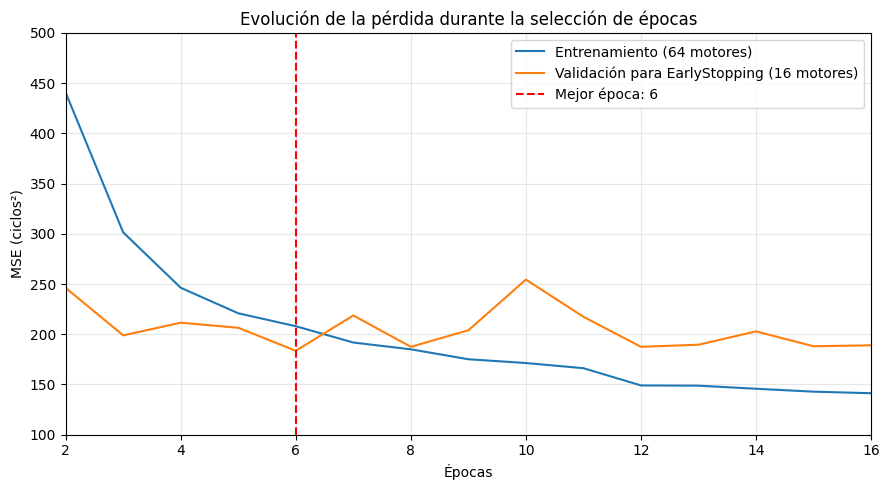

In [ ]:
# Evolución del entrenamiento inicial de la LSTM
epochs_range = range(
    1, len(history_lstm.history["loss"]) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    history_lstm.history["loss"],
    label="Entrenamiento (64 motores)"
)

plt.plot(
    epochs_range,
    history_lstm.history["val_loss"],
    label="Validación para EarlyStopping (16 motores)"
)

plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Mejor época: {best_epoch}"
)

plt.xlabel("Épocas")
plt.ylabel("MSE (ciclos²)")
plt.title("Evolución de la pérdida durante la selección de épocas")
plt.legend()
plt.grid(alpha=0.3)

# Ampliar la zona donde se observan las diferencias de pérdida
plt.xlim(2, len(history_lstm.history["loss"]))
plt.ylim(100, 500)

plt.tight_layout()
plt.show()

El procedimiento de entrenamiento se ha desarrollado en dos fases para evitar que los motores reservados para la evaluación interna intervengan en la selección del número de épocas.

En la primera fase, se utilizaron 64 motores para el entrenamiento de la LSTM y 16 motores independientes para supervisar la evolución de la pérdida de validación. Se generaron 11.304 secuencias de entrenamiento y 2.937 secuencias de validación.

El entrenamiento inicial finalizó tras 16 épocas debido al mecanismo `EarlyStopping`. La menor pérdida de validación se alcanzó en la época 6, con un MSE de 183,5502 ciclos² y un MAE de 9,9982 ciclos.

La gráfica de evolución de la pérdida muestra una reducción pronunciada del error durante las primeras épocas. Posteriormente, la pérdida de entrenamiento continúa disminuyendo, mientras que la pérdida de validación presenta fluctuaciones y alcanza su mínimo en la época 6, con un MSE de 183,5502 ciclos².

A partir de esta época, las mejoras obtenidas sobre los datos de entrenamiento no se traducen en una reducción sostenida del error de validación, lo que sugiere un posible sobreajuste al prolongar el entrenamiento. Este comportamiento respalda la selección de seis épocas para entrenar posteriormente el modelo con los 80 motores de desarrollo.

Una vez seleccionado el número de épocas, se inicializó una nueva instancia de la misma arquitectura LSTM y se entrenó utilizando las 14.241 secuencias correspondientes a los 80 motores de desarrollo.

Este segundo entrenamiento se realizó durante 6 épocas y obtuvo una pérdida final de entrenamiento de 201,5352 ciclos² y un MAE de 10,7710 ciclos.

Estas últimas métricas corresponden exclusivamente a los datos de entrenamiento y no constituyen una evaluación de la capacidad de generalización del modelo.

El procedimiento permite conservar los 20 motores de evaluación interna fuera del entrenamiento y de la selección del número de épocas. Por tanto, el modelo resultante queda preparado para evaluar posteriormente su capacidad predictiva sobre motores independientes.

En los siguientes apartados se evaluará la capacidad predictiva de la LSTM sobre los 20 motores reservados y se comparará posteriormente su rendimiento con el de los modelos de Machine Learning utilizando las mismas observaciones de validación.

### 6.4. Evaluación del modelo LSTM

Una vez finalizado el entrenamiento de la LSTM con los 80 motores de desarrollo durante el número de épocas seleccionado previamente, se evalúa su capacidad predictiva sobre las 3.490 secuencias correspondientes a los 20 motores reservados para la evaluación interna.

Estos 20 motores no han intervenido en el entrenamiento del modelo ni en la selección del número de épocas, que se realizó mediante una división adicional de los motores de desarrollo. De esta forma, se evita utilizar las mismas observaciones para seleccionar los pesos del modelo y evaluar posteriormente su rendimiento.

Se utilizan las mismas métricas empleadas para los modelos anteriores: MAE, RMSE y R², calculadas respecto a la variable objetivo `RUL_piecewise`, limitada a 120 ciclos.

El MAE permite cuantificar el error absoluto medio de las estimaciones de RUL, mientras que el RMSE penaliza en mayor medida las predicciones con errores elevados. Por su parte, el coeficiente R² permite analizar el ajuste respecto a la variabilidad de la variable objetivo.

Esta evaluación proporciona una medida del rendimiento del modelo temporal sobre motores independientes de los utilizados durante su desarrollo. Posteriormente, sus resultados se compararán con los modelos de Machine Learning utilizando exactamente los mismos motores y ciclos, garantizando una comparación homogénea entre ambos enfoques.

In [ ]:
# Predicciones de la LSTM sobre validación interna
y_pred_lstm = model_lstm.predict(
    X_val_seq,
    verbose=0
).ravel()

# Comprobaciones
assert len(y_pred_lstm) == len(y_val_seq)
assert np.isfinite(y_pred_lstm).all()

# Métricas
mae_lstm = mean_absolute_error(
    y_val_seq, y_pred_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(y_val_seq, y_pred_lstm)
)

r2_lstm = r2_score(
    y_val_seq, y_pred_lstm
)

print("EVALUACIÓN LSTM")
print("Observaciones:", len(y_val_seq))
print(f"MAE: {mae_lstm:.4f} ciclos")
print(f"RMSE: {rmse_lstm:.4f} ciclos")
print(f"R²: {r2_lstm:.4f}")

print("\nRANGO DE PREDICCIONES")
print(f"Mínimo: {y_pred_lstm.min():.4f}")
print(f"Máximo: {y_pred_lstm.max():.4f}")

EVALUACIÓN LSTM
Observaciones: 3490
MAE: 8.1934 ciclos
RMSE: 11.2370 ciclos
R²: 0.9217

RANGO DE PREDICCIONES
Mínimo: 3.1449
Máximo: 124.2940


La evaluación del modelo LSTM, entrenado con los 80 motores de desarrollo durante las 6 épocas seleccionadas previamente, se ha realizado sobre 3.490 secuencias correspondientes a los 20 motores reservados para evaluación interna.

Se ha obtenido un MAE de 8,1934 ciclos, un RMSE de 11,2370 ciclos y un coeficiente R² de 0,9217.

El MAE indica que las predicciones presentan un error absoluto medio de aproximadamente 8,19 ciclos respecto a los valores de `RUL_piecewise`. Por su parte, el RMSE refleja la mayor penalización de los errores de predicción elevados.

El coeficiente R² indica que el modelo explica aproximadamente el 92,17 % de la variabilidad de la RUL limitada en las observaciones evaluadas.

En cuanto al rango de predicciones, se ha obtenido un valor mínimo de 3,1449 ciclos y un máximo de 124,2940 ciclos. Este último supera ligeramente el límite de 120 ciclos establecido para la variable objetivo, debido a que la capa de salida utiliza una activación lineal que no restringe el intervalo de predicción.

Estos resultados corresponden a un modelo cuyo número de épocas se ha seleccionado exclusivamente mediante una división interna de los motores de desarrollo. Por tanto, los 20 motores de evaluación no han intervenido en el entrenamiento ni en la selección del número de épocas.

Aunque los resultados muestran una capacidad predictiva relevante sobre los motores evaluados, todavía es necesario realizar una comparación homogénea con los modelos de Machine Learning, utilizando exactamente las mismas observaciones de validación.

### 6.5. Comparación de los modelos sobre las mismas observaciones

Para comparar de manera homogénea los modelos de Machine Learning y Deep Learning, se seleccionan las observaciones de validación correspondientes a las ventanas temporales utilizadas por la LSTM.

Debido a que las ventanas tienen una longitud de 30 ciclos y no se utiliza relleno, las primeras 29 observaciones de cada motor quedan excluidas de esta comparación.

Los modelos clásicos realizarán sus predicciones utilizando únicamente los sensores del último ciclo de cada ventana, mientras que la LSTM utilizará la secuencia completa de 30 ciclos.

De esta forma, todos los modelos se evaluarán sobre las mismas 3.490 observaciones y con los mismos valores reales de `RUL_piecewise`, utilizando las métricas MAE, RMSE y R².

Se mantendrán los modelos previamente entrenados, sin realizar nuevos ajustes ni utilizar el conjunto oficial de test.

In [ ]:
# Identificar los ciclos utilizados por la LSTM
val_common = val_internal.merge(
    val_seq_info,
    on=["unit", "cycle"],
    how="inner",
    validate="one_to_one"
)

# Conservar el orden exacto de las ventanas LSTM
val_common = val_seq_info.merge(
    val_common,
    on=["unit", "cycle"],
    how="left",
    validate="one_to_one",
    sort=False
)

# Recuperar los sensores originales de esos mismos ciclos
val_raw_common = val_seq_info.merge(
    val_raw_internal,
    on=["unit", "cycle"],
    how="left",
    validate="one_to_one",
    sort=False
)

X_common_raw = val_raw_common[sensor_features].copy()

# Escalado utilizado por los modelos iniciales
X_common_scaled = pd.DataFrame(
    scaler_rul.transform(X_common_raw),
    columns=sensor_features
)

# Valores reales
y_common = val_common[target].to_numpy()

# Comprobar correspondencia con las etiquetas LSTM
assert len(y_common) == len(y_val_seq) == 3490
assert np.array_equal(y_common, y_val_seq)
assert not X_common_raw.isnull().any().any()

# Reunir predicciones de todos los modelos
predictions_common = {
    "Baseline (media)": baseline.predict(X_common_scaled),
    "Regresión lineal": trained_models_ml[
        "Regresión lineal"
    ].predict(X_common_scaled),
    "Random Forest": trained_models_ml[
        "Random Forest"
    ].predict(X_common_scaled),
    "Gradient Boosting": trained_models_ml[
        "Gradient Boosting"
    ].predict(X_common_scaled),
    "Random Forest (optimizado)": optimized_models_ml[
        "Random Forest"
    ].predict(X_common_raw),
    "Gradient Boosting (optimizado)": optimized_models_ml[
        "Gradient Boosting"
    ].predict(X_common_raw),
    "LSTM": y_pred_lstm
}

# Evaluación homogénea
results_common = []

for name, predictions in predictions_common.items():

    results_common.append({
        "Modelo": name,
        "MAE": mean_absolute_error(y_common, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_common, predictions)
        ),
        "R2": r2_score(y_common, predictions)
    })

results_common_df = pd.DataFrame(results_common)

print("COMPARACIÓN HOMOGÉNEA")
print("Observaciones evaluadas:", len(y_common))
print("Motores:", val_common["unit"].nunique())

display(
    results_common_df.sort_values("MAE").round(4)
)

COMPARACIÓN HOMOGÉNEA
Observaciones evaluadas: 3490
Motores: 20


,Modelo,MAE,RMSE,R2
6,LSTM,8.1934,11.2370,0.9217
4,Random Forest (optimizado),11.8973,16.5672,0.8299
2,Random Forest,11.9893,16.6719,0.8277
5,Gradient Boosting (optimizado),12.0016,16.5382,0.8305
3,Gradient Boosting,12.0906,16.5907,0.8294
1,Regresión lineal,15.4095,19.1311,0.7732
0,Baseline (media),35.3184,40.6916,-0.0262


La comparación homogénea se ha realizado sobre 3.490 observaciones correspondientes a los mismos 20 motores de evaluación interna. De esta forma, todos los modelos se evalúan utilizando idénticos valores reales de `RUL_piecewise`.

Los resultados muestran que la arquitectura LSTM presenta los menores errores entre los modelos evaluados, con un MAE de 8,1934 ciclos, un RMSE de 11,2370 ciclos y un coeficiente R² de 0,9217.

Entre los modelos clásicos, Random Forest optimizado obtiene el menor MAE, con 11,8973 ciclos, mientras que Gradient Boosting optimizado alcanza el menor RMSE, con 16,5382 ciclos, y el mayor R², con 0,8305, dentro de este grupo de modelos.

En comparación con Random Forest optimizado, la LSTM reduce el MAE aproximadamente un 31,13 % y el RMSE un 32,17 %. Además, incrementa el coeficiente R² de 0,8299 a 0,9217.

Estos resultados sugieren que el procesamiento de secuencias temporales puede aportar información relevante para la estimación de la vida útil restante de los motores. En particular, el análisis conjunto de 30 ciclos consecutivos permite utilizar la evolución reciente de las mediciones de los sensores.

No obstante, las diferencias observadas no pueden atribuirse exclusivamente a la incorporación de información temporal, puesto que también existen diferencias entre las arquitecturas y sus procedimientos de entrenamiento.

Asimismo, las métricas corresponden a una única partición de evaluación interna de 20 motores. Aunque estos motores permanecieron excluidos del entrenamiento y de la selección de épocas de la LSTM, los resultados de esta evaluación se utilizan para comparar y seleccionar modelos. Por tanto, será necesario evaluar posteriormente el modelo seleccionado sobre el conjunto oficial de test FD001 para estudiar su comportamiento en motores no utilizados durante el desarrollo.

En conjunto, la comparación muestra que la LSTM obtiene menores errores que los modelos clásicos evaluados sobre las mismas observaciones, por lo que constituye una alternativa relevante para continuar el análisis de prognosis.

## 7. Selección y entrenamiento del modelo final

Tras desarrollar y evaluar diferentes algoritmos de Machine Learning y Deep Learning, se procede a seleccionar el modelo que se utilizará para la evaluación externa de la vida útil restante de los motores.

La selección se realiza a partir de los resultados obtenidos sobre los 20 motores de validación interna, considerando las métricas MAE, RMSE y R².

Una vez seleccionada la arquitectura, se realizará un entrenamiento final utilizando los 100 motores disponibles en `train_FD001`, manteniendo completamente separado el conjunto oficial de test.

### 7.1. Selección del modelo de prognosis

La comparación homogénea entre los modelos desarrollados se ha realizado sobre 3.490 observaciones correspondientes a los mismos 20 motores de evaluación interna, utilizando las métricas MAE, RMSE y R².

Entre los modelos clásicos, Random Forest optimizado ha obtenido el menor MAE, con 11,8973 ciclos. Por su parte, la arquitectura LSTM ha alcanzado un MAE de 8,1934 ciclos, un RMSE de 11,2370 ciclos y un coeficiente R² de 0,9217.

Estos resultados representan una reducción aproximada del 31,13 % en el MAE de la LSTM respecto a Random Forest optimizado.

Por tanto, se selecciona la arquitectura LSTM como modelo de prognosis para la evaluación externa, al haber obtenido los menores errores de predicción durante la comparación interna.

Es importante destacar que los 20 motores de evaluación interna no participaron en el entrenamiento de la LSTM ni en la selección de su número de épocas. Sin embargo, sus resultados sí se han utilizado para comparar las distintas arquitecturas y seleccionar el modelo final.

En consecuencia, esta selección queda pendiente de contrastarse mediante una evaluación externa sobre el conjunto oficial de test FD001, formado por motores que no han intervenido en el desarrollo ni en la selección de modelos.

### 7.2. Preparación de los datos para el entrenamiento final

Una vez seleccionada la arquitectura LSTM, se prepara el conjunto completo de entrenamiento FD001, formado por 100 motores y 20.631 observaciones.

Para evitar fugas de información, se utilizan los valores originales de los 14 sensores seleccionados y se ajusta un nuevo `StandardScaler` exclusivamente sobre las observaciones de estos 100 motores.

La variable objetivo continúa siendo `RUL_piecewise`, limitada a un máximo de 120 ciclos.

Posteriormente, se generan ventanas temporales de 30 ciclos consecutivos por motor, siguiendo el mismo procedimiento utilizado durante la validación interna.

Se mantiene la arquitectura previamente seleccionada y se fija la duración del entrenamiento a partir de la fase de desarrollo, sin utilizar los datos oficiales de test para tomar decisiones sobre los hiperparámetros.

In [ ]:
# Recuperar los valores originales de los 100 motores
X_full_raw = train_raw[sensor_features].copy()

# Etiquetas de RUL correspondientes
full_targets = train[
    ["unit", "cycle", target]
].copy()

# Comprobar correspondencia de las observaciones
assert train_raw[["unit", "cycle"]].reset_index(
    drop=True
).equals(
    train[["unit", "cycle"]].reset_index(drop=True)
)

# Ajustar un nuevo escalador con los 100 motores
scaler_rul_final = StandardScaler()

X_full_scaled = pd.DataFrame(
    scaler_rul_final.fit_transform(X_full_raw),
    columns=sensor_features,
    index=train_raw.index
)

# Construir el conjunto completo
train_lstm_final_data = full_targets.copy()

train_lstm_final_data[sensor_features] = (
    X_full_scaled[sensor_features]
)

# Generar ventanas temporales
X_train_final_seq, y_train_final_seq, train_final_info = (
    create_sequences(
        train_lstm_final_data,
        sensor_features,
        target,
        WINDOW_SIZE
    )
)

# Comprobaciones
print("ENTRENAMIENTO FINAL")
print("Motores:", train_final_info["unit"].nunique())
print("X_train_final_seq:", X_train_final_seq.shape)
print("y_train_final_seq:", y_train_final_seq.shape)

print("\nCOMPROBACIONES")
print(
    "Valores nulos:",
    np.isnan(X_train_final_seq).sum()
)

print(
    "Ventanas esperadas:",
    len(train) - (WINDOW_SIZE - 1) * train["unit"].nunique()
)

ENTRENAMIENTO FINAL
Motores: 100
X_train_final_seq: (17731, 30, 14)
y_train_final_seq: (17731,)

COMPROBACIONES
Valores nulos: 0
Ventanas esperadas: 17731


La preparación del conjunto completo de entrenamiento ha generado 17.731 secuencias temporales correspondientes a los 100 motores de FD001.

Cada secuencia contiene 30 ciclos consecutivos y las mediciones de los 14 sensores seleccionados. La variable objetivo corresponde a la RUL limitada del último ciclo de cada ventana.

El número de secuencias coincide con el esperado, considerando que se descartan los primeros 29 ciclos de cada motor al no disponer de una ventana temporal completa.

Se ha comprobado que no existen valores nulos y que el escalado se ha ajustado exclusivamente utilizando los datos originales de los 100 motores de entrenamiento.

Por tanto, el conjunto queda preparado para entrenar el modelo LSTM definitivo, manteniendo separado el conjunto oficial de test.

### 7.3. Entrenamiento definitivo del modelo LSTM

Una vez preparado el conjunto completo de entrenamiento, se procede a entrenar la arquitectura LSTM seleccionada utilizando las 17.731 secuencias correspondientes a los 100 motores de FD001.

Se mantiene la arquitectura definida durante la fase de desarrollo, compuesta por una capa LSTM de 64 unidades, una capa Dropout de 0,2, una capa densa de 32 neuronas con activación ReLU y una capa de salida lineal.

Para garantizar que el entrenamiento definitivo comienza desde cero, se crea una nueva instancia del modelo, sin reutilizar los pesos aprendidos durante las fases anteriores.

Se utiliza el optimizador Adam, con una tasa de aprendizaje inicial de 0,001, el error cuadrático medio (MSE) como función de pérdida y un tamaño de lote de 64 secuencias.

La duración del entrenamiento se establece a partir del procedimiento de selección de épocas desarrollado en el apartado 6.3. En dicho procedimiento, se utilizaron 64 motores para el entrenamiento inicial y 16 motores independientes para supervisar la pérdida de validación mediante EarlyStopping.

La menor pérdida de validación se alcanzó en la época 6, por lo que se establece esta duración para el entrenamiento definitivo sobre los 100 motores.

En esta fase no se utiliza EarlyStopping ni se reserva un conjunto adicional de validación, puesto que el número de épocas ya se ha determinado previamente y se pretende aprovechar la totalidad de los datos de entrenamiento disponibles.

El conjunto oficial de test permanece completamente separado y no interviene en el entrenamiento ni en la selección de hiperparámetros.

In [ ]:
# Semilla para mejorar la reproducibilidad
tf.keras.utils.set_random_seed(42)

# Crear una nueva instancia de la arquitectura
model_lstm_final = Sequential([
    Input(shape=(WINDOW_SIZE, len(sensor_features))),

    LSTM(64),

    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1, activation="linear")
])

# Compilar el modelo definitivo
model_lstm_final.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Entrenar con los 100 motores
history_lstm_final = model_lstm_final.fit(
    X_train_final_seq,
    y_train_final_seq,
    epochs=best_epoch,  # 6 épocas seleccionadas en el apartado 6.3
    batch_size=64,
    shuffle=True,
    verbose=1
)

# Resumen del entrenamiento
print("\nENTRENAMIENTO DEFINITIVO LSTM")
print(
    "Épocas ejecutadas:",
    len(history_lstm_final.history["loss"])
)

print(
    "MSE final de entrenamiento:",
    round(history_lstm_final.history["loss"][-1], 4)
)

print(
    "MAE final de entrenamiento:",
    round(history_lstm_final.history["mae"][-1], 4)
)

Epoch 1/6
278/278 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 2196.3113 - mae: 35.5480
Epoch 2/6
278/278 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 281.5182 - mae: 13.0649
Epoch 3/6
278/278 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 225.1406 - mae: 11.4512
Epoch 4/6
278/278 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 192.1150 - mae: 10.5025
Epoch 5/6
278/278 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 177.2745 - mae: 10.0310
Epoch 6/6
278/278 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 172.6284 - mae: 9.8842

ENTRENAMIENTO DEFINITIVO LSTM
Épocas ejecutadas: 6
MSE final de entrenamiento: 172.6284
MAE final de entrenamiento: 9.8842


El entrenamiento definitivo de la arquitectura LSTM se ha completado utilizando las 17.731 secuencias temporales correspondientes a los 100 motores del conjunto de entrenamiento FD001.

Se han ejecutado las 6 épocas seleccionadas previamente mediante el procedimiento de validación interna desarrollado en el apartado 6.3, manteniendo la arquitectura y los hiperparámetros establecidos durante la fase de desarrollo.

Durante el entrenamiento se observa una disminución progresiva de las métricas de error. El error absoluto medio (MAE) se ha reducido de 35,5480 ciclos en la primera época a 9,8842 ciclos en la última, mientras que el error cuadrático medio (MSE) ha disminuido de 2.196,3113 a 172,6284 ciclos².

La reducción más pronunciada se produce durante las primeras épocas, seguida de mejoras progresivamente menores conforme avanza el entrenamiento. Este comportamiento indica que la red neuronal ha conseguido ajustar sus parámetros a los patrones presentes en las secuencias temporales de los motores.

El modelo definitivo se ha entrenado desde cero utilizando la totalidad de los 100 motores disponibles, con un nuevo escalador ajustado exclusivamente sobre el conjunto completo de entrenamiento.

No obstante, las métricas obtenidas corresponden al propio proceso de entrenamiento y no permiten determinar de forma independiente la capacidad de generalización del modelo.

Por este motivo, el siguiente paso consiste en realizar una evaluación externa sobre los motores del conjunto oficial `test_FD001`, que no han participado en el entrenamiento ni en la selección de la arquitectura y los hiperparámetros.

## 8. Evaluación externa sobre el conjunto oficial de test FD001

Una vez seleccionado y entrenado el modelo LSTM definitivo, se procede a evaluar su capacidad de generalización utilizando el conjunto oficial de test FD001, compuesto por 100 motores que no han participado en las fases de entrenamiento, validación ni selección del modelo.

A diferencia del conjunto de entrenamiento, que contiene las trayectorias completas de los motores hasta su fallo, el conjunto de test incluye trayectorias parciales que finalizan antes de producirse el fallo. Para conocer la vida útil restante real, se utilizará el archivo `RUL_FD001.txt`, que proporciona la RUL correspondiente al último ciclo registrado de cada motor.

En primer lugar, se reconstruirá la RUL de las observaciones disponibles y se aplicará el límite de 120 ciclos utilizado durante el entrenamiento. Posteriormente, se prepararán las secuencias temporales de 30 ciclos utilizando los mismos 14 sensores seleccionados y el escalador ajustado exclusivamente con los datos de entrenamiento.

La evaluación principal se realizará sobre la última observación disponible de cada uno de los 100 motores, siguiendo el planteamiento de prognosis del conjunto C-MAPSS. Adicionalmente, se analizará la distribución de los errores de predicción, diferenciando entre sobreestimaciones y subestimaciones de la vida útil restante, y se estudiará el rendimiento del modelo según distintos intervalos de RUL.

El rendimiento se cuantificará mediante las métricas MAE, RMSE y R², permitiendo analizar la precisión de las estimaciones de RUL sobre motores independientes.

Esta evaluación permitirá comprobar si los resultados obtenidos durante la validación interna se mantienen al aplicar el modelo a datos no utilizados durante su desarrollo.

### 8.1. Reconstrucción de la RUL oficial del test

El conjunto oficial de test FD001 contiene las trayectorias parciales de 100 motores, cuyas observaciones finalizan antes de producirse el fallo.

A diferencia del conjunto de entrenamiento, estas trayectorias no incluyen directamente la vida útil restante de cada ciclo.

Para reconstruirla, se utiliza el archivo `RUL_FD001.txt`, que proporciona la RUL correspondiente a la última observación disponible de cada motor.

La RUL de los ciclos anteriores se obtiene sumando a dicho valor la diferencia entre el último ciclo observado y el ciclo correspondiente.

Posteriormente, se aplica el mismo límite de 120 ciclos utilizado durante el entrenamiento, obteniendo la variable `RUL_piecewise` para el conjunto de test.

Esta transformación garantiza que las predicciones del modelo se evalúen frente a una variable objetivo coherente con la utilizada durante el aprendizaje.

In [ ]:
# Cargar las etiquetas oficiales de RUL del test
rul_test_official = pd.read_csv(
    f"{RAW_DATA_PATH}/RUL_FD001.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

# Asociar cada etiqueta con su motor (1 a 100)
rul_test_df = pd.DataFrame({
    "unit": np.arange(1, len(rul_test_official) + 1),
    "RUL_final": rul_test_official.to_numpy()
})

# Comprobar correspondencia de motores
assert len(rul_test_df) == test["unit"].nunique()
assert set(rul_test_df["unit"]) == set(test["unit"].unique())

# Reconstruir etiquetas por ciclo
test_rul = test[["unit", "cycle"]].copy()

test_rul = test_rul.merge(
    rul_test_df,
    on="unit",
    how="left",
    validate="many_to_one"
)

# Último ciclo observado de cada motor
test_rul["max_cycle"] = (
    test_rul.groupby("unit")["cycle"].transform("max")
)

# RUL original reconstruida
test_rul["RUL_original"] = (
    test_rul["RUL_final"]
    + test_rul["max_cycle"]
    - test_rul["cycle"]
)

# Aplicar el límite de 120 ciclos
test_rul["RUL_piecewise"] = (
    test_rul["RUL_original"].clip(upper=120)
)

# Comprobaciones
assert len(test_rul) == len(test)
assert test_rul["RUL_piecewise"].notna().all()
assert (test_rul["RUL_original"] >= 0).all()
assert test_rul["RUL_piecewise"].between(0, 120).all()

# Verificar la RUL del último ciclo de cada motor
last_cycles = test_rul.loc[
    test_rul.groupby("unit")["cycle"].idxmax()
].sort_values("unit")

assert np.array_equal(
    last_cycles["RUL_original"].to_numpy(),
    rul_test_df.sort_values("unit")["RUL_final"].to_numpy()
)

print("RECONSTRUCCIÓN RUL TEST FD001")
print("Motores:", test_rul["unit"].nunique())
print("Observaciones:", len(test_rul))

print("\nDISTRIBUCIÓN RUL ORIGINAL")
print(test_rul["RUL_original"].describe())

print("\nDISTRIBUCIÓN RUL PIECEWISE")
print(test_rul["RUL_piecewise"].describe())

print("\nComprobación de RUL final oficial: correcta")

RECONSTRUCCIÓN RUL TEST FD001
Motores: 100
Observaciones: 13096

DISTRIBUCIÓN RUL ORIGINAL
count    13096.000000
mean       141.238470
std         58.980114
min          7.000000
25%        102.000000
50%        140.000000
75%        179.000000
max        340.000000
Name: RUL_original, dtype: float64

DISTRIBUCIÓN RUL PIECEWISE
count    13096.000000
mean       105.782300
std         25.801895
min          7.000000
25%        102.000000
50%        120.000000
75%        120.000000
max        120.000000
Name: RUL_piecewise, dtype: float64

Comprobación de RUL final oficial: correcta


La reconstrucción de la RUL del conjunto oficial de test FD001 se ha realizado correctamente, obteniendo 13.096 observaciones correspondientes a 100 motores.

La RUL original reconstruida presenta valores comprendidos entre 7 y 340 ciclos, con una media de 141,24 ciclos y una desviación estándar de 58,98 ciclos.

Tras aplicar el límite superior de 120 ciclos, la variable `RUL_piecewise` presenta una media de 105,78 ciclos y una desviación estándar de 25,80 ciclos, manteniendo un mínimo de 7 ciclos y un máximo de 120 ciclos.

Esta transformación reduce la variabilidad de la variable objetivo, especialmente en las etapas iniciales de funcionamiento, donde la vida útil restante es elevada.

Se ha comprobado que los valores reconstruidos en el último ciclo observado de cada motor coinciden exactamente con los proporcionados por el archivo oficial `RUL_FD001.txt`.

Por tanto, las etiquetas del conjunto de test quedan preparadas para evaluar el modelo LSTM definitivo. Las métricas principales se calcularán utilizando `RUL_piecewise`, de manera coherente con la variable objetivo empleada durante el entrenamiento.

### 8.2. Preparación de las secuencias temporales del test

Una vez reconstruidas las etiquetas de RUL, se preparan las variables predictoras del conjunto oficial de test para su utilización en el modelo LSTM definitivo.

Se recuperan los valores originales de los 14 sensores seleccionados y se aplica el escalador `scaler_rul_final`, previamente ajustado sobre los 100 motores del conjunto de entrenamiento.

De esta forma, el conjunto de test no interviene en el cálculo de los parámetros de estandarización.

Posteriormente, se generan ventanas temporales de 30 ciclos consecutivos por motor, utilizando el mismo procedimiento aplicado durante el entrenamiento.

Cada secuencia se asocia a la RUL limitada correspondiente a su último ciclo. Además, se conservan los identificadores de motor y ciclo para facilitar la evaluación y el análisis posterior de los resultados.

Se comprobarán las dimensiones de las secuencias, la ausencia de valores nulos y la correspondencia entre las ventanas generadas y las observaciones originales.

In [ ]:
# Recuperar los valores originales del test ya preprocesado
test_raw = test[
    ["unit", "cycle"] + sensor_features
].copy()

# Comprobar correspondencia con las etiquetas reconstruidas
assert test_raw[["unit", "cycle"]].reset_index(
    drop=True
).equals(
    test_rul[["unit", "cycle"]].reset_index(drop=True)
)

# Comprobar que los sensores están disponibles
assert not test_raw[sensor_features].isnull().any().any()

print("Datos originales del test preparados correctamente.")
print("Observaciones:", len(test_raw))
print("Sensores seleccionados:", len(sensor_features))
print("Correspondencia con etiquetas RUL: correcta")

Datos originales del test preparados correctamente.
Observaciones: 13096
Sensores seleccionados: 14
Correspondencia con etiquetas RUL: correcta


In [ ]:
# Aplicar el escalador del entrenamiento definitivo
X_test_scaled = pd.DataFrame(
    scaler_rul_final.transform(
        test_raw[sensor_features]
    ),
    columns=sensor_features,
    index=test_raw.index
)

# Construir conjunto de test para LSTM
test_lstm_data = test_rul[
    ["unit", "cycle", "RUL_piecewise"]
].copy()

test_lstm_data[sensor_features] = (
    X_test_scaled[sensor_features]
)

# Generar ventanas temporales
X_test_seq, y_test_seq, test_seq_info = create_sequences(
    test_lstm_data,
    sensor_features,
    target,
    WINDOW_SIZE
)

# Comprobaciones
assert len(X_test_seq) == len(y_test_seq)
assert np.isfinite(X_test_seq).all()
assert np.isfinite(y_test_seq).all()

assert set(test_seq_info["unit"]) == set(test["unit"])

# Verificar que cada motor tiene una ventana final
last_test_cycles = test.groupby("unit")["cycle"].max()

last_seq_cycles = (
    test_seq_info.groupby("unit")["cycle"].max()
)

assert last_test_cycles.equals(last_seq_cycles)

print("SECUENCIAS TEST FD001")
print("Motores:", test_seq_info["unit"].nunique())
print("X_test_seq:", X_test_seq.shape)
print("y_test_seq:", y_test_seq.shape)

print("\nCOMPROBACIONES")
print(
    "Valores nulos:",
    np.isnan(X_test_seq).sum()
)

print(
    "Ventanas esperadas:",
    len(test) - (WINDOW_SIZE - 1) * test["unit"].nunique()
)

print(
    "Último ciclo disponible por motor:",
    "correctamente incluido"
)

SECUENCIAS TEST FD001
Motores: 100
X_test_seq: (10196, 30, 14)
y_test_seq: (10196,)

COMPROBACIONES
Valores nulos: 0
Ventanas esperadas: 10196
Último ciclo disponible por motor: correctamente incluido


La preparación del conjunto oficial de test FD001 ha generado 10.196 secuencias temporales correspondientes a 100 motores.

Cada secuencia contiene 30 ciclos consecutivos y las mediciones de los 14 sensores seleccionados. Las variables predictoras se han estandarizado utilizando exclusivamente el escalador ajustado durante el entrenamiento definitivo, sin recalcular sus parámetros sobre el conjunto de test.

El número de secuencias coincide con el esperado tras descartar los primeros 29 ciclos de cada motor. Asimismo, se ha comprobado la ausencia de valores nulos y se ha verificado que la última observación disponible de cada motor está representada en las secuencias generadas.

Por tanto, los datos quedan preparados para realizar la evaluación externa del modelo LSTM definitivo.

### 8.3. Evaluación externa del modelo LSTM

Una vez preparadas las secuencias temporales del conjunto oficial de test, se evalúa la capacidad de generalización del modelo LSTM definitivo.

Siguiendo el planteamiento de prognosis del dataset C-MAPSS, la evaluación principal se realiza sobre la última observación disponible de cada uno de los 100 motores.

Para ello, se selecciona la última ventana temporal de 30 ciclos de cada motor y se utiliza el modelo entrenado para estimar su vida útil restante.

Las predicciones se comparan con los valores reales de `RUL_piecewise`, obtenidos a partir del archivo oficial `RUL_FD001.txt` y limitados a 120 ciclos, de forma coherente con la variable objetivo utilizada durante el entrenamiento.

El rendimiento se cuantifica mediante las métricas MAE, RMSE y R².

Esta evaluación constituye una prueba externa del modelo, ya que los motores del conjunto oficial de test no han participado en su entrenamiento, validación ni selección.

In [ ]:
# Identificar la última ventana de cada motor
last_window_indices = (
    test_seq_info.groupby("unit")["cycle"].idxmax()
    .to_numpy()
)

# Seleccionar las últimas ventanas
X_test_final = X_test_seq[last_window_indices]
y_test_final = y_test_seq[last_window_indices]

# Información de los motores evaluados
test_final_info = (
    test_seq_info.iloc[last_window_indices]
    .reset_index(drop=True)
)

# Comprobar dimensiones
assert X_test_final.shape == (
    100, WINDOW_SIZE, len(sensor_features)
)

assert len(y_test_final) == 100
assert test_final_info["unit"].nunique() == 100

# Realizar predicciones con la LSTM definitiva
y_pred_test_final = (
    model_lstm_final.predict(
        X_test_final,
        verbose=0
    ).ravel()
)

# Calcular métricas
mae_test_final = mean_absolute_error(
    y_test_final,
    y_pred_test_final
)

rmse_test_final = np.sqrt(
    mean_squared_error(
        y_test_final,
        y_pred_test_final
    )
)

r2_test_final = r2_score(
    y_test_final,
    y_pred_test_final
)

# Guardar resultados por motor
test_predictions_df = test_final_info.copy()

test_predictions_df["RUL_real"] = y_test_final
test_predictions_df["RUL_predicha"] = y_pred_test_final

test_predictions_df["Error_absoluto"] = np.abs(
    y_test_final - y_pred_test_final
)

# Mostrar resultados
print("EVALUACIÓN EXTERNA LSTM - FD001")
print("Motores evaluados:", len(y_test_final))

print("\nMÉTRICAS")
print(f"MAE:  {mae_test_final:.4f} ciclos")
print(f"RMSE: {rmse_test_final:.4f} ciclos")
print(f"R²:   {r2_test_final:.4f}")

print("\nRANGO DE PREDICCIONES")
print(
    f"Mínimo: {y_pred_test_final.min():.4f}"
)
print(
    f"Máximo: {y_pred_test_final.max():.4f}"
)

print("\nPRIMEROS 10 MOTORES")
display(
    test_predictions_df.head(10).round(2)
)

EVALUACIÓN EXTERNA LSTM - FD001
Motores evaluados: 100

MÉTRICAS
MAE:  8.7094 ciclos
RMSE: 12.1846 ciclos
R²:   0.9041

RANGO DE PREDICCIONES
Mínimo: 7.3457
Máximo: 119.5020

PRIMEROS 10 MOTORES


,unit,cycle,RUL_real,RUL_predicha,Error_absoluto
0,1,31,112.0,113.440002,1.440000
1,2,49,98.0,114.750000,16.750000
2,3,126,69.0,46.360001,22.639999
3,4,106,82.0,84.660004,2.660000
4,5,98,91.0,105.760002,14.760000
5,6,105,93.0,104.389999,11.390000
6,7,160,91.0,99.820000,8.820000
7,8,166,95.0,92.050003,2.950000
8,9,55,111.0,112.089996,1.090000
9,10,192,96.0,86.519997,9.480000


La evaluación externa del modelo LSTM definitivo, entrenado durante 6 épocas con los 100 motores del conjunto de entrenamiento FD001, se ha realizado sobre los 100 motores independientes del conjunto oficial de test, utilizando la última ventana temporal disponible de cada motor.

El modelo ha obtenido un MAE de 8,7094 ciclos, un RMSE de 12,1846 ciclos y un coeficiente R² de 0,9041.

Estos resultados indican que el modelo consigue estimar la vida útil restante limitada con un error absoluto medio de aproximadamente 8,71 ciclos. Asimismo, el coeficiente R² indica que el modelo explica aproximadamente el 90,41 % de la variabilidad de `RUL_piecewise` en los motores evaluados.

Las predicciones obtenidas se encuentran comprendidas entre 7,3457 y 119,5020 ciclos, sin presentar valores negativos ni superiores al límite de 120 ciclos utilizado durante el entrenamiento.

En comparación con la validación interna, donde la LSTM obtuvo un MAE de 8,1934 ciclos, un RMSE de 11,2370 ciclos y un R² de 0,9217, se observa un ligero incremento de los errores durante la evaluación externa. No obstante, ambas evaluaciones utilizan protocolos diferentes: la validación interna considera múltiples ventanas por motor, mientras que la evaluación oficial utiliza una única predicción por motor, correspondiente a su último ciclo observado. Por tanto, las diferencias no deben interpretarse como una medida directa de pérdida de rendimiento entre ambos conjuntos.

El análisis inicial de las predicciones individuales muestra diferencias entre motores, incluyendo casos con errores reducidos y otros con desviaciones superiores a 20 ciclos.

En conjunto, los resultados muestran que la arquitectura LSTM desarrollada mantiene una capacidad predictiva elevada sobre motores independientes de los utilizados durante su desarrollo.

No obstante, las métricas globales no permiten identificar por sí solas posibles desviaciones importantes en motores concretos. Por este motivo, en el siguiente apartado se analizará la distribución de los errores, diferenciando entre sobreestimaciones y subestimaciones de la vida útil restante.

### 8.4. Análisis de errores por motor

Tras evaluar el rendimiento global del modelo LSTM, se realiza un análisis detallado de los errores obtenidos en los 100 motores del conjunto oficial de test.

El objetivo es identificar la distribución de los errores absolutos, detectar motores con predicciones especialmente alejadas de los valores reales y diferenciar entre sobreestimaciones y subestimaciones de la vida útil restante.

Esta distinción resulta relevante en mantenimiento predictivo, puesto que sobreestimar la RUL puede retrasar una intervención, mientras que subestimarla puede adelantar innecesariamente las operaciones de mantenimiento.

Para ello, se calculan los errores firmados y absolutos, así como diferentes indicadores descriptivos que permiten caracterizar el comportamiento del modelo.

In [ ]:
# Calcular el error firmado:
  # positivo = sobreestimación de RUL
  # negativo = subestimación de RUL

test_predictions_df["Error_firmado"] = (
    test_predictions_df["RUL_predicha"]
    - test_predictions_df["RUL_real"]
)

# Resumen estadístico
print("ANÁLISIS DE ERRORES - TEST FD001")

print("\nDISTRIBUCIÓN DEL ERROR ABSOLUTO")
print(
    test_predictions_df["Error_absoluto"]
    .describe()
    .round(4)
)

# Sobreestimaciones y subestimaciones
n_over = (
    test_predictions_df["Error_firmado"] > 0
).sum()

n_under = (
    test_predictions_df["Error_firmado"] < 0
).sum()

print("\nTIPOS DE ERROR")
print(f"Sobreestimaciones: {n_over}")
print(f"Subestimaciones: {n_under}")

print(
    "Error firmado medio:",
    round(
        test_predictions_df["Error_firmado"].mean(),
        4
    )
)

# Errores elevados
print("\nMOTORES CON ERROR ABSOLUTO > 20 CICLOS")

large_errors = test_predictions_df[
    test_predictions_df["Error_absoluto"] > 20
].sort_values(
    "Error_absoluto",
    ascending=False
)

print("Número de motores:", len(large_errors))

display(
    large_errors[
        [
            "unit",
            "RUL_real",
            "RUL_predicha",
            "Error_firmado",
            "Error_absoluto"
        ]
    ].round(2)
)

ANÁLISIS DE ERRORES - TEST FD001

DISTRIBUCIÓN DEL ERROR ABSOLUTO
count    100.0000
mean       8.7094
std        8.5640
min        0.0313
25%        2.3020
50%        6.0449
75%       13.1349
max       40.5153
Name: Error_absoluto, dtype: float64

TIPOS DE ERROR
Sobreestimaciones: 48
Subestimaciones: 52
Error firmado medio: -0.853

MOTORES CON ERROR ABSOLUTO > 20 CICLOS
Número de motores: 6


,unit,RUL_real,RUL_predicha,Error_firmado,Error_absoluto
44,45,114.0,73.480003,-40.520000,40.520000
92,93,85.0,45.150002,-39.849998,39.849998
66,67,77.0,113.849998,36.849998,36.849998
26,27,66.0,94.550003,28.549999,28.549999
78,79,63.0,90.559998,27.559999,27.559999
2,3,69.0,46.360001,-22.639999,22.639999


El análisis individual de los 100 motores del conjunto oficial de test FD001 permite estudiar la distribución de los errores de predicción y detectar posibles desviaciones relevantes para una aplicación de mantenimiento predictivo.

El error absoluto medio obtenido es de 8,7094 ciclos, mientras que la mediana se sitúa en 6,0449 ciclos. El primer cuartil corresponde a 2,3020 ciclos y el tercero a 13,1349 ciclos, lo que indica que el 75 % de los motores presenta errores absolutos inferiores o iguales a aproximadamente 13,13 ciclos.

La desviación estándar del error absoluto es de 8,5640 ciclos, con valores comprendidos entre 0,0313 y 40,5153 ciclos. Esta dispersión evidencia que, aunque una parte importante de las predicciones presenta errores reducidos, existen casos individuales con desviaciones considerables.

Respecto al sentido del error, se han identificado 48 sobreestimaciones y 52 subestimaciones de la RUL. El error firmado medio es de −0,8530 ciclos, lo que refleja una ligera tendencia global a subestimar la vida útil restante, aunque las desviaciones positivas y negativas se compensan parcialmente.

Asimismo, se han detectado 6 motores con errores absolutos superiores a 20 ciclos, equivalentes al 6 % del conjunto evaluado.

Entre los casos más destacados se encuentra el motor 45, cuya RUL real es de 114 ciclos y cuya predicción es de aproximadamente 73,48 ciclos, dando lugar a una subestimación de 40,52 ciclos. También destaca el motor 93, con una RUL real de 85 ciclos y una predicción de 45,15 ciclos, lo que supone una subestimación de 39,85 ciclos.

Por otra parte, el motor 67 presenta una RUL real de 77 ciclos frente a una predicción de 113,85 ciclos, dando lugar a una sobreestimación de 36,85 ciclos.

Desde el punto de vista del mantenimiento predictivo, ambos tipos de error tienen implicaciones diferentes. Las subestimaciones pueden provocar intervenciones anticipadas, mientras que las sobreestimaciones pueden retrasar actuaciones de mantenimiento, especialmente cuando el sistema predice una vida útil considerablemente superior a la real.

Por tanto, aunque el modelo presenta un error absoluto medio relativamente reducido, el análisis individual demuestra la importancia de considerar tanto los errores elevados como su dirección antes de utilizar las estimaciones de RUL como apoyo a decisiones operativas.

Estos resultados permiten identificar limitaciones del modelo y contextualizar su aplicación, sin utilizar las observaciones del conjunto oficial de test para modificar los parámetros previamente seleccionados.

### 8.5. Análisis del error según la vida útil restante

Para profundizar en la evaluación externa del modelo LSTM, se analiza el comportamiento de las predicciones en función de la vida útil restante real de los motores.

El objetivo es comprobar si la precisión del modelo varía según el nivel de RUL y determinar si existen intervalos en los que las estimaciones presentan mayores desviaciones.

Para ello, se agrupan los motores en cuatro intervalos de RUL limitada: 0-30, 31-60, 61-90 y 91-120 ciclos.

En cada intervalo se calcula el número de motores, el error absoluto medio (MAE), el RMSE y el error firmado medio.

Este análisis permite complementar las métricas globales e identificar posibles diferencias de rendimiento según la proximidad al fallo.

In [ ]:
# Definir intervalos de RUL real
rul_bins = [-0.1, 30, 60, 90, 120]

rul_labels = [
    "0-30",
    "31-60",
    "61-90",
    "91-120"
]

# Asignar cada motor a un intervalo
test_predictions_df["Intervalo_RUL"] = pd.cut(
    test_predictions_df["RUL_real"],
    bins=rul_bins,
    labels=rul_labels,
    include_lowest=True
)

# Calcular métricas por intervalo
results_by_rul = []

for interval_name, group in test_predictions_df.groupby(
    "Intervalo_RUL",
    observed=True
):
    results_by_rul.append({
        "Intervalo_RUL": str(interval_name),
        "Motores": len(group),
        "MAE": mean_absolute_error(
            group["RUL_real"],
            group["RUL_predicha"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                group["RUL_real"],
                group["RUL_predicha"]
            )
        ),
        "Error_firmado_medio": (
            group["Error_firmado"].mean()
        )
    })

results_by_rul_df = pd.DataFrame(results_by_rul)

print("ERRORES SEGÚN LA RUL REAL")
display(results_by_rul_df.round(4))

print("\nCOMPROBACIÓN")
print(
    "Total de motores analizados:",
    results_by_rul_df["Motores"].sum()
)

ERRORES SEGÚN LA RUL REAL


,Intervalo_RUL,Motores,MAE,RMSE,Error_firmado_medio
0,0-30,25,2.2531,2.9956,0.4765
1,31-60,14,9.6281,11.4236,2.1973
2,61-90,15,15.7499,20.0213,7.2557
3,91-120,46,9.6429,12.1425,-5.1480



COMPROBACIÓN
Total de motores analizados: 100


El análisis del error según la vida útil restante revela diferencias en el rendimiento del modelo LSTM entre los distintos intervalos de RUL.

En el intervalo de 0 a 30 ciclos, correspondiente a los motores más próximos al fallo, se obtiene el menor MAE, con 2,2531 ciclos, y un RMSE de 2,9956 ciclos. Este grupo está formado por 25 motores y presenta un error firmado medio de 0,4765 ciclos, próximo a cero.

En el intervalo de 31 a 60 ciclos, compuesto por 14 motores, el MAE aumenta hasta 9,6281 ciclos y el RMSE hasta 11,4236 ciclos. El error firmado medio es de 2,1973 ciclos, lo que indica una ligera tendencia a sobreestimar la vida útil restante en este grupo.

Las mayores desviaciones se observan en el intervalo de 61 a 90 ciclos, donde los 15 motores evaluados presentan un MAE de 15,7499 ciclos y un RMSE de 20,0213 ciclos. Además, el error firmado medio de 7,2557 ciclos indica una tendencia a sobreestimar la vida útil restante en este intervalo.

Por último, el intervalo de 91 a 120 ciclos contiene 46 motores y presenta un MAE de 9,6429 ciclos, un RMSE de 12,1425 ciclos y un error firmado medio de −5,1480 ciclos. Este último resultado refleja una tendencia a subestimar la RUL limitada en los motores de este grupo.

Los resultados muestran que la precisión del modelo no es uniforme en los distintos intervalos de vida útil restante. Destaca especialmente el reducido error observado en los motores con una RUL de entre 0 y 30 ciclos, un comportamiento relevante para las aplicaciones de mantenimiento predictivo, donde resulta importante estimar adecuadamente la proximidad al fallo.

Sin embargo, en el intervalo de 61 a 90 ciclos se observa una mayor dificultad para realizar estimaciones precisas. La tendencia a sobreestimar la vida útil en este grupo merece especial atención, puesto que podría traducirse en intervenciones de mantenimiento más tardías si las predicciones se utilizaran directamente para tomar decisiones operativas.

No obstante, los intervalos contienen cantidades diferentes de motores y las conclusiones se limitan al conjunto oficial de test FD001. Además, el uso de una RUL limitada a 120 ciclos condiciona especialmente la interpretación del último intervalo, que también incluye motores cuya vida útil restante original supera dicho límite.

En conjunto, este análisis complementa las métricas globales y permite identificar tanto los intervalos en los que el modelo presenta menores errores como aquellos en los que se observan mayores desviaciones, aportando información sobre las limitaciones de las predicciones de RUL.

### 8.6. Comparación externa con un modelo de referencia

Para contextualizar el rendimiento obtenido por la arquitectura LSTM en la evaluación externa, se establece una comparación con un modelo de referencia basado en la predicción constante de la RUL media del conjunto de entrenamiento.

Se utiliza `DummyRegressor` con la estrategia `mean`, ajustado exclusivamente sobre los datos de los 100 motores de entrenamiento FD001.

La comparación se realiza sobre las mismas 100 observaciones del conjunto oficial de test utilizadas para evaluar la LSTM, correspondientes al último ciclo disponible de cada motor.

Se calculan las métricas MAE, RMSE y R² de ambos modelos sobre la variable objetivo `RUL_piecewise`.

Este procedimiento permite comprobar la mejora obtenida respecto a una estrategia predictiva sencilla, sin utilizar información del conjunto de test durante el ajuste del modelo de referencia.

In [ ]:
# Modelo de referencia entrenado con los 100 motores
baseline_final = DummyRegressor(strategy="mean")

# La predicción constante se ajusta utilizando exclusivamente las etiquetas de entrenamiento
baseline_final.fit(
    np.zeros((len(y_train_final_seq), 1)),
    y_train_final_seq
)

# Predecir la RUL de los 100 motores oficiales
y_pred_baseline_final = baseline_final.predict(
    np.zeros((len(y_test_final), 1))
)

# Calcular métricas del baseline
mae_baseline_final = mean_absolute_error(
    y_test_final,
    y_pred_baseline_final
)

rmse_baseline_final = np.sqrt(
    mean_squared_error(
        y_test_final,
        y_pred_baseline_final
    )
)

r2_baseline_final = r2_score(
    y_test_final,
    y_pred_baseline_final
)

# Comparación externa
results_external = pd.DataFrame([
    {
        "Modelo": "Baseline (media)",
        "MAE": mae_baseline_final,
        "RMSE": rmse_baseline_final,
        "R2": r2_baseline_final
    },
    {
        "Modelo": "LSTM definitiva",
        "MAE": mae_test_final,
        "RMSE": rmse_test_final,
        "R2": r2_test_final
    }
])

# Reducción porcentual de los errores
reduction_mae = (
    (mae_baseline_final - mae_test_final)
    / mae_baseline_final
) * 100

reduction_rmse = (
    (rmse_baseline_final - rmse_test_final)
    / rmse_baseline_final
) * 100

print("COMPARACIÓN EXTERNA - TEST FD001")
print("Motores evaluados:", len(y_test_final))

print("\nRESULTADOS")
display(results_external.round(4))

print("\nMEJORA DE LSTM RESPECTO AL BASELINE")
print(f"Reducción MAE: {reduction_mae:.2f}%")
print(f"Reducción RMSE: {reduction_rmse:.2f}%")

print("\nPREDICCIÓN CONSTANTE DEL BASELINE")
print(f"{baseline_final.constant_[0, 0]:.4f} ciclos")

COMPARACIÓN EXTERNA - TEST FD001
Motores evaluados: 100

RESULTADOS


,Modelo,MAE,RMSE,R2
0,Baseline (media),34.6417,39.6902,-0.0177
1,LSTM definitiva,8.7094,12.1846,0.9041



MEJORA DE LSTM RESPECTO AL BASELINE
Reducción MAE: 74.86%
Reducción RMSE: 69.30%

PREDICCIÓN CONSTANTE DEL BASELINE
79.0828 ciclos


La comparación externa se ha realizado sobre los 100 motores del conjunto oficial de test FD001, utilizando las mismas observaciones y etiquetas para ambos modelos.

El modelo de referencia, basado en `DummyRegressor` con estrategia `mean`, genera una predicción constante de 79,0828 ciclos, calculada exclusivamente a partir de las etiquetas de entrenamiento asociadas a las secuencias temporales.

Este modelo obtiene un MAE de 34,6417 ciclos, un RMSE de 39,6902 ciclos y un coeficiente R² de −0,0177.

Por su parte, la arquitectura LSTM definitiva, entrenada durante 6 épocas con los 100 motores de entrenamiento FD001, obtiene un MAE de 8,7094 ciclos, un RMSE de 12,1846 ciclos y un R² de 0,9041.

En comparación con el baseline, la LSTM consigue reducir el MAE un 74,86 % y el RMSE un 69,30 %.

Estos resultados muestran que el modelo LSTM proporciona estimaciones de la vida útil restante considerablemente más precisas que una estrategia basada únicamente en la media de las etiquetas de entrenamiento.

Asimismo, el coeficiente R² de 0,9041 indica que las predicciones de la LSTM explican aproximadamente el 90,41 % de la variabilidad de `RUL_piecewise` entre los motores evaluados. Por el contrario, el valor negativo obtenido por el baseline refleja su limitada capacidad para representar las diferencias individuales de vida útil restante.

No obstante, el baseline constituye una referencia sencilla y no un modelo predictivo competitivo. Por tanto, estos resultados deben interpretarse conjuntamente con la comparación entre algoritmos realizada durante la validación interna, donde también se evaluaron modelos de regresión lineal, Random Forest y Gradient Boosting.

Además, la evaluación externa utiliza únicamente la última observación disponible de cada motor, por lo que sus resultados caracterizan el rendimiento en ese punto de predicción y no todas las etapas de las trayectorias de funcionamiento.

En conjunto, la evaluación externa aporta evidencia de la capacidad de generalización de la arquitectura LSTM desarrollada sobre los motores independientes del conjunto oficial de test FD001 y respalda su utilización como base para continuar investigando la prognosis de fallos mediante series temporales multivariantes.

## 9. Conclusiones de la prognosis

En este notebook se ha desarrollado y evaluado un sistema de estimación de la vida útil restante (Remaining Useful Life, RUL) de motores turbofán utilizando el conjunto de datos NASA C-MAPSS FD001.

El trabajo ha abordado la prognosis como un problema de regresión supervisada, utilizando 14 sensores seleccionados durante el preprocesamiento y una variable objetivo `RUL_piecewise` limitada a 120 ciclos.

### 9.1. Comparación de modelos predictivos

Inicialmente, se han desarrollado diferentes modelos de Machine Learning, incluyendo regresión lineal, Random Forest y Gradient Boosting.

Posteriormente, se han optimizado los hiperparámetros de Random Forest y Gradient Boosting mediante validación cruzada agrupada por motor, evitando que las observaciones de un mismo motor aparezcan simultáneamente en los subconjuntos de entrenamiento y validación de cada partición.

Además, se ha desarrollado una arquitectura LSTM capaz de procesar secuencias temporales de 30 ciclos consecutivos. Para seleccionar el número de épocas, se ha utilizado una división adicional de los motores de desarrollo, reservando los 20 motores de evaluación interna para la comparación posterior de los modelos.

En la comparación homogénea sobre 3.490 observaciones de validación interna, la LSTM ha obtenido un MAE de 8,1934 ciclos, un RMSE de 11,2370 ciclos y un R² de 0,9217.

Entre los modelos clásicos, Random Forest optimizado ha obtenido el menor MAE, con 11,8973 ciclos. En comparación con este modelo, la LSTM ha conseguido reducir el MAE aproximadamente un 31,13 %.

Estos resultados muestran que la arquitectura LSTM ha obtenido menores errores que los modelos clásicos evaluados sobre las mismas observaciones, lo que sugiere que el aprovechamiento de información temporal puede resultar beneficioso para la estimación de RUL.

No obstante, las diferencias observadas no pueden atribuirse exclusivamente a la incorporación de información temporal, puesto que también existen diferencias entre las arquitecturas y sus procedimientos de entrenamiento.

### 9.2. Evaluación externa del modelo seleccionado

Tras seleccionar la arquitectura LSTM, se ha realizado un entrenamiento definitivo utilizando los 100 motores disponibles en el conjunto de entrenamiento FD001.

Se ha mantenido la arquitectura desarrollada previamente y se ha establecido una duración de 6 épocas, seleccionada durante la fase de desarrollo mediante validación interna, sin utilizar el conjunto oficial de test para determinar este parámetro.

La evaluación externa se ha efectuado sobre los 100 motores independientes del conjunto oficial de test, utilizando la última ventana temporal disponible de cada motor.

El modelo definitivo ha obtenido los siguientes resultados:

- MAE: 8,7094 ciclos.
- RMSE: 12,1846 ciclos.
- R²: 0,9041.

Estos resultados muestran que el modelo consigue estimar la RUL limitada con un error absoluto medio inferior a 9 ciclos sobre los motores evaluados.

El coeficiente R² indica que el modelo explica aproximadamente el 90,41 % de la variabilidad de `RUL_piecewise` en este conjunto de evaluación.

En comparación con la validación interna, se observa un ligero incremento de los errores. No obstante, ambas evaluaciones utilizan protocolos diferentes: la validación interna considera múltiples ventanas por motor, mientras que la evaluación oficial utiliza una única predicción por motor, correspondiente a su último ciclo observado. Por tanto, estas diferencias no deben interpretarse directamente como una pérdida de rendimiento entre ambos conjuntos.

### 9.3. Análisis de errores

El análisis individual ha permitido comprobar que el 75 % de los motores presenta errores absolutos inferiores o iguales a aproximadamente 13,13 ciclos, mientras que la mediana del error absoluto se sitúa en 6,0449 ciclos.

Sin embargo, se han identificado 6 motores con errores superiores a 20 ciclos, equivalentes al 6 % del conjunto evaluado. El mayor error absoluto registrado alcanza aproximadamente 40,52 ciclos.

Asimismo, se han registrado 48 sobreestimaciones y 52 subestimaciones, con un error firmado medio de −0,8530 ciclos. Este resultado refleja una ligera tendencia global a subestimar la vida útil restante, aunque existen desviaciones individuales importantes en ambos sentidos.

El análisis por intervalos de RUL muestra que el menor error se obtiene en los motores próximos al fallo, con un MAE de 2,2531 ciclos para el intervalo de 0 a 30 ciclos.

Por el contrario, el intervalo de 61 a 90 ciclos presenta el mayor MAE, con 15,7499 ciclos, y un error firmado medio de 7,2557 ciclos, lo que indica una tendencia a sobreestimar la vida útil restante en este grupo.

En el intervalo de 91 a 120 ciclos se observa una tendencia media a la subestimación, con un error firmado medio de −5,1480 ciclos.

Estos resultados muestran que la precisión del modelo no es uniforme en los distintos intervalos de vida útil restante.

Desde el punto de vista del mantenimiento predictivo, ambos tipos de error tienen implicaciones diferentes. Las sobreestimaciones pueden retrasar intervenciones necesarias, mientras que las subestimaciones pueden provocar actuaciones anticipadas.

Por tanto, el análisis realizado pone de manifiesto la importancia de complementar las métricas globales con el estudio de los errores individuales, su dirección y su posible impacto operativo.

### 9.4. Comparación con el modelo de referencia

Finalmente, se ha comparado la LSTM con un modelo de referencia basado en `DummyRegressor`, que predice de forma constante la RUL media de las secuencias de entrenamiento.

Este modelo genera una predicción constante de 79,0828 ciclos y obtiene un MAE de 34,6417 ciclos, un RMSE de 39,6902 ciclos y un coeficiente R² de −0,0177 sobre los 100 motores del conjunto oficial de test.

Por su parte, la arquitectura LSTM definitiva obtiene un MAE de 8,7094 ciclos, un RMSE de 12,1846 ciclos y un R² de 0,9041.

En comparación con el baseline, la LSTM ha reducido el MAE un 74,86 % y el RMSE un 69,30 %.

Estos resultados muestran que el modelo desarrollado aprovecha información predictiva presente en las mediciones de los sensores y obtiene estimaciones considerablemente más precisas que una estrategia basada únicamente en el valor medio de entrenamiento.

No obstante, el baseline constituye una referencia sencilla y no un modelo predictivo competitivo. Por tanto, estos resultados deben interpretarse conjuntamente con la comparación entre algoritmos realizada durante la validación interna, donde también se evaluaron modelos de regresión lineal, Random Forest y Gradient Boosting.

### 9.5. Limitaciones y consideraciones futuras

Aunque los resultados obtenidos son favorables, deben considerarse algunas limitaciones.

En primer lugar, la evaluación se ha realizado exclusivamente sobre FD001, un subconjunto de C-MAPSS con una única condición operativa y un único modo de fallo simulado. Por tanto, los resultados no pueden generalizarse directamente a sistemas industriales con condiciones de funcionamiento más heterogéneas.

En segundo lugar, la variable objetivo se ha limitado a un máximo de 120 ciclos, por lo que el modelo no distingue valores de RUL superiores a dicho límite.

Además, la evaluación externa principal utiliza una única predicción por motor, correspondiente a su última observación disponible.

Por último, aunque la LSTM ha superado a los modelos clásicos durante la validación interna, no se ha realizado una comparación externa entre todos ellos utilizando los 100 motores oficiales de test.

Como posibles líneas de trabajo futuras se plantea estudiar otros subconjuntos de C-MAPSS, analizar arquitecturas temporales alternativas e incorporar estimaciones de incertidumbre que permitan identificar predicciones menos fiables.

### 9.6. Conclusión general

Los resultados obtenidos muestran que es posible desarrollar un modelo de prognosis basado en Deep Learning capaz de estimar la vida útil restante de motores turbofán a partir de series temporales multivariantes.

La arquitectura LSTM ha presentado un rendimiento favorable tanto durante la validación interna como en la evaluación externa sobre motores independientes.

El análisis realizado proporciona una base experimental para incorporar la estimación de RUL a una herramienta de mantenimiento predictivo, complementando las funcionalidades de detección de anomalías y monitorización del estado de los equipos.

No obstante, su aplicación a sistemas industriales reales requeriría validaciones adicionales, una evaluación de la incertidumbre y el establecimiento de criterios operativos adecuados.

## 10. Guardado del modelo de prognosis

Una vez finalizado el entrenamiento y la evaluación externa, se guardan los elementos necesarios para reutilizar el modelo de prognosis en la herramienta de mantenimiento predictivo.

El objetivo es conservar tanto el modelo LSTM definitivo como los parámetros de preprocesamiento y la configuración utilizada durante su desarrollo.

Para ello, se almacenan los siguientes componentes:

- **Modelo LSTM:** arquitectura y pesos entrenados utilizando los 100 motores del conjunto de entrenamiento FD001.
- **Escalador:** objeto `StandardScaler` ajustado exclusivamente sobre los datos originales de entrenamiento.
- **Configuración:** listado y orden de los 14 sensores, longitud de las ventanas temporales y límite superior de RUL.

El modelo se guarda en formato `.keras`, el escalador mediante `joblib` y la configuración en formato JSON.

Estos archivos permitirán cargar el sistema de prognosis posteriormente y generar estimaciones de vida útil restante sin necesidad de repetir el entrenamiento.

In [ ]:
# Directorio de modelos de prognosis
PROGNOSIS_MODELS_PATH = (
    "/content/drive/MyDrive/TFM/models/prognosis"
)

os.makedirs(
    PROGNOSIS_MODELS_PATH,
    exist_ok=True
)

# Rutas de los archivos
MODEL_PATH = os.path.join(
    PROGNOSIS_MODELS_PATH,
    "lstm_RUL_FD001.keras"
)

SCALER_PATH = os.path.join(
    PROGNOSIS_MODELS_PATH,
    "scaler_RUL_FD001.pkl"
)

CONFIG_PATH = os.path.join(
    PROGNOSIS_MODELS_PATH,
    "config_RUL_FD001.json"
)

# 1. Guardar modelo LSTM
model_lstm_final.save(MODEL_PATH)

# 2. Guardar escalador
joblib.dump(
    scaler_rul_final,
    SCALER_PATH
)

# 3. Guardar configuración
config_rul = {
    "dataset": "C-MAPSS FD001",
    "model_type": "LSTM",
    "sensor_features": sensor_features,
    "window_size": WINDOW_SIZE,
    "rul_cap": 120,
    "target": "RUL_piecewise",
    "n_training_engines": 100,
    "training_epochs": int(best_epoch),
    "batch_size": 64
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(
        config_rul,
        f,
        indent=4,
        ensure_ascii=False
    )

print("MODELO DE PROGNOSIS GUARDADO")

print("\nModelo:")
print(MODEL_PATH)

print("\nEscalador:")
print(SCALER_PATH)

print("\nConfiguración:")
print(CONFIG_PATH)

MODELO DE PROGNOSIS GUARDADO

Modelo:
/content/drive/MyDrive/TFM/models/prognosis/lstm_RUL_FD001.keras

Escalador:
/content/drive/MyDrive/TFM/models/prognosis/scaler_RUL_FD001.pkl

Configuración:
/content/drive/MyDrive/TFM/models/prognosis/config_RUL_FD001.json


### 10.1. Verificación de los archivos guardados

Tras exportar el modelo de prognosis, se comprueba que los archivos se han almacenado correctamente y pueden recuperarse desde Google Drive.

Se carga nuevamente el modelo LSTM, el escalador y el archivo de configuración.

Posteriormente, se realizan predicciones sobre las mismas 100 ventanas finales del conjunto oficial de test, utilizando el modelo recuperado.

Las predicciones se comparan con las obtenidas antes de guardar el modelo, verificando que el proceso de exportación y carga no ha modificado su comportamiento.

Esta comprobación permite validar la persistencia de los componentes necesarios para integrar el sistema de prognosis en la herramienta final.

In [ ]:
# Comprobar existencia de archivos
for path in [MODEL_PATH, SCALER_PATH, CONFIG_PATH]:
    assert os.path.isfile(path), (
        f"No se encuentra el archivo: {path}"
    )

# Recuperar modelo
model_lstm_loaded = load_model(
    MODEL_PATH
)

# Recuperar escalador
scaler_rul_loaded = joblib.load(
    SCALER_PATH
)

# Recuperar configuración
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config_rul_loaded = json.load(f)

# Verificar configuración
assert (
    config_rul_loaded["sensor_features"]
    == sensor_features
)

assert (
    config_rul_loaded["window_size"]
    == WINDOW_SIZE
)

assert (
    config_rul_loaded["rul_cap"]
    == 120
)

assert (
    scaler_rul_loaded.n_features_in_
    == len(sensor_features)
)

# Comprobar épocas del entrenamiento definitivo
assert (
    config_rul_loaded["training_epochs"]
    == int(best_epoch)
)

# Verificar también el orden de sensores del escalador
assert (
    list(scaler_rul_loaded.feature_names_in_)
    == sensor_features
)

# Predecir con el modelo recuperado
y_pred_loaded = model_lstm_loaded.predict(
    X_test_final,
    verbose=0
).ravel()

# Comparar con las predicciones originales
max_prediction_diff = np.max(
    np.abs(
        y_pred_loaded - y_pred_test_final
    )
)

assert np.allclose(
    y_pred_loaded,
    y_pred_test_final,
    rtol=1e-5,
    atol=1e-5
)

print("VERIFICACIÓN DEL MODELO GUARDADO")

print("\nArchivos encontrados: 3/3")

print(
    "Sensores configurados:",
    len(config_rul_loaded["sensor_features"])
)

print(
    "Ventana temporal:",
    config_rul_loaded["window_size"]
)

print(
    "Límite RUL:",
    config_rul_loaded["rul_cap"]
)

print(
    "\nDiferencia máxima entre predicciones:",
    f"{max_prediction_diff:.10f}"
)

print("\nVerificación completada correctamente.")

VERIFICACIÓN DEL MODELO GUARDADO

Archivos encontrados: 3/3
Sensores configurados: 14
Ventana temporal: 30
Límite RUL: 120

Diferencia máxima entre predicciones: 0.0000000000

Verificación completada correctamente.


La exportación del modelo de prognosis se ha completado correctamente, almacenando los tres componentes necesarios para su reutilización: el modelo LSTM definitivo, el escalador de las variables predictoras y el archivo de configuración.

El modelo se ha guardado en formato `.keras`, el escalador en formato `.pkl` y la configuración en formato `.json`, dentro del directorio `models/prognosis` del proyecto.

La verificación posterior ha confirmado la existencia y correcta recuperación de los tres archivos.

Asimismo, se ha comprobado que la configuración recuperada contiene los 14 sensores seleccionados, una longitud de ventana temporal de 30 ciclos, un límite superior de RUL de 120 ciclos y el número de épocas establecido durante el desarrollo del modelo.

Para verificar la persistencia del modelo, se han generado nuevamente las predicciones sobre las 100 ventanas finales del conjunto oficial de test FD001 utilizando el modelo recuperado.

La diferencia máxima entre las predicciones originales y las obtenidas después de cargar el modelo ha sido de 0, confirmando que el proceso de exportación y recuperación conserva su comportamiento predictivo para las entradas evaluadas.

Por tanto, los componentes del sistema de prognosis quedan almacenados y verificados para su posterior integración en la herramienta de mantenimiento predictivo.

Durante dicha integración será necesario garantizar que las nuevas observaciones se procesen utilizando el mismo escalador, orden de sensores y procedimiento de construcción de ventanas temporales empleados durante el entrenamiento. También deberá verificarse el funcionamiento del proceso completo, desde la recepción de las mediciones originales hasta la generación de la predicción de RUL.